# FFT-based Adaptive KV Compression

```
K, V -> rFFT(head_dim) -> frequency selector -> mask -> irFFT -> existing attention
```
- All existing model weights frozen; only the selector is trained
- Sections 2-8 use head_dim-axis FFT as in the plan; sequence-axis FFT from Section 9

## Selector insertion point
- transformers v5 `Qwen3Attention.forward`: right after applying RoPE, a single line `past_key_values.update(key_states, value_states, layer_idx)` updates the cache, and attention is computed from its return value
- Wrapping just `DynamicCache.update` swaps both the KV stored in the cache and the KV attention reads

## 0. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import torch

import tools
from custom_layers import FFTCompressedCache, KVFreqCompressor, SparseSpectralCache

MODEL = "Qwen/Qwen3-0.6B"   # bf16. FP8 checkpoint excluded: no backprop through to the selector
CORPUS = "gutenberg"       
SEQ_LEN = 256
BATCH_SIZE = 2
N_BATCHES = 100             # train 90 + val 10
EPOCHS = 3
LR = 3e-4

QUICK = False               # True = reduced settings, structure check only
if QUICK:
    SEQ_LEN, BATCH_SIZE, N_BATCHES, EPOCHS = 128, 1, 20, 1

RESULTS = Path("results")
(RESULTS / "selectors").mkdir(parents=True, exist_ok=True)
summary: dict = {}          # measurements saved to json at the end

tools.set_seed(0)
print(torch.__version__, torch.cuda.get_device_name(0))

2.14.1+cu130 NVIDIA GeForce RTX 5080


## 1. Model and data

- teacher and student use the same weights
- selector added to the student only; existing weights stay fixed during training too
- Output difference between the two models = difference caused by compression

In [2]:
model, tok = tools.load_model(MODEL)
info = tools.describe_model(model)
info

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

{'layers': 28,
 'hidden': 1024,
 'q_heads': 16,
 'kv_heads': 8,
 'head_dim': 128,
 'n_freq': 65,
 'vocab': 151936,
 'dtype': 'torch.bfloat16'}

In [3]:
# freeze check
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable in base model: {n_train} ")
print(f"head_dim={info['head_dim']}  ->  {info['n_freq']} rFFT coefficients (bin 0 .. {info['head_dim']//2})")

trainable in base model: 0 
head_dim=128  ->  65 rFFT coefficients (bin 0 .. 64)


In [4]:
text = tools.load_text(CORPUS)
batches = tools.make_batches(tok, text, seq_len=SEQ_LEN, batch_size=BATCH_SIZE,
                             n_batches=N_BATCHES, device=model.device)
n_val = max(2, N_BATCHES // 10)
train_batches, val_batches = batches[:-n_val], batches[-n_val:]
print(f"{len(text):,} chars -> {len(batches)} batches of {tuple(batches[0].shape)}"
      f"  (train {len(train_batches)} / val {len(val_batches)})")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (174851 > 131072). Running this sequence through the model will result in indexing errors


748,167 chars -> 100 batches of (2, 256)  (train 90 / val 10)


## 2. Hypothesis check

Hypothesis: moving K/V latents to the FFT basis concentrates the information needed for downstream prediction in a few frequencies

1. **Energy distribution** — fraction of energy held by the top m coefficients by magnitude
2. **Truncation sensitivity** — output damage when coefficients are cut without training
3. **Per-layer sensitivity** — output damage when only one layer is cut

Three untrained baselines (used in items 2 and 3, and as the reference in later sections)
- energy: top k coefficients by magnitude. Data-driven, adaptive
- lowpass: k lowest frequencies. Fixed rule
- random: k at random. Control

cache: (1, 8, 256, 128) (batch, heads, seq, head_dim)

[Layer  0 Keys  ] len=262144  rfft bins=131073  DC=24508.16  IFFT max err=3.05e-05
    bin    9984  freq 0.038086  (period      26.3 samples)  |X|=332972.66
    bin  119040  freq 0.454102  (period       2.2 samples)  |X|=331716.72
    bin   98560  freq 0.375977  (period       2.7 samples)  |X|=328810.38
    bin   14080  freq 0.053711  (period      18.6 samples)  |X|=326871.69
    bin  110848  freq 0.422852  (period       2.4 samples)  |X|=325833.91
[Layer  0 Values] len=262144  rfft bins=131073  DC=682.81  IFFT max err=2.38e-07
    bin   57856  freq 0.220703  (period       4.5 samples)  |X|=920.08
    bin  129536  freq 0.494141  (period       2.0 samples)  |X|=912.52
    bin  103936  freq 0.396484  (period       2.5 samples)  |X|=901.18
    bin   96512  freq 0.368164  (period       2.7 samples)  |X|=726.48
    bin   96000  freq 0.366211  (period       2.7 samples)  |X|=702.38


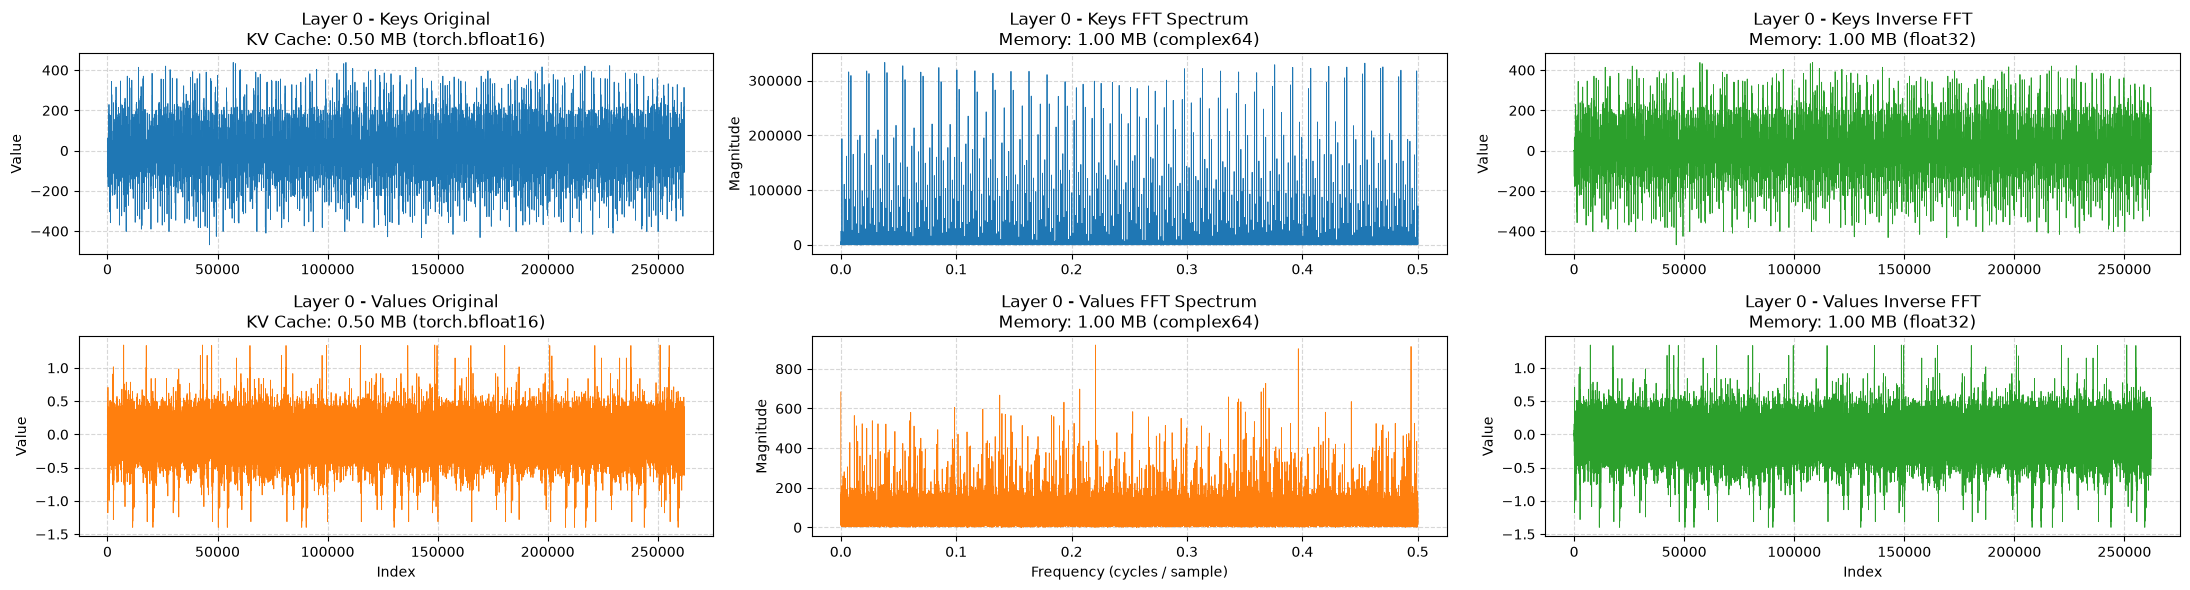

[Layer  7 Keys  ] len=262144  rfft bins=131073  DC=9621.21  IFFT max err=1.14e-05
    bin   52992  freq 0.202148  (period       4.9 samples)  |X|=91692.84
    bin  116992  freq 0.446289  (period       2.2 samples)  |X|=81878.30
    bin   47360  freq 0.180664  (period       5.5 samples)  |X|=81756.24
    bin  112384  freq 0.428711  (period       2.3 samples)  |X|=81116.29
    bin  116480  freq 0.444336  (period       2.3 samples)  |X|=80568.27
[Layer  7 Values] len=262144  rfft bins=131073  DC=1243.66  IFFT max err=4.77e-07
    bin   50176  freq 0.191406  (period       5.2 samples)  |X|=3319.22
    bin   64256  freq 0.245117  (period       4.1 samples)  |X|=3209.78
    bin   95488  freq 0.364258  (period       2.7 samples)  |X|=3170.68
    bin  124672  freq 0.475586  (period       2.1 samples)  |X|=3093.48
    bin   22528  freq 0.085938  (period      11.6 samples)  |X|=3083.66


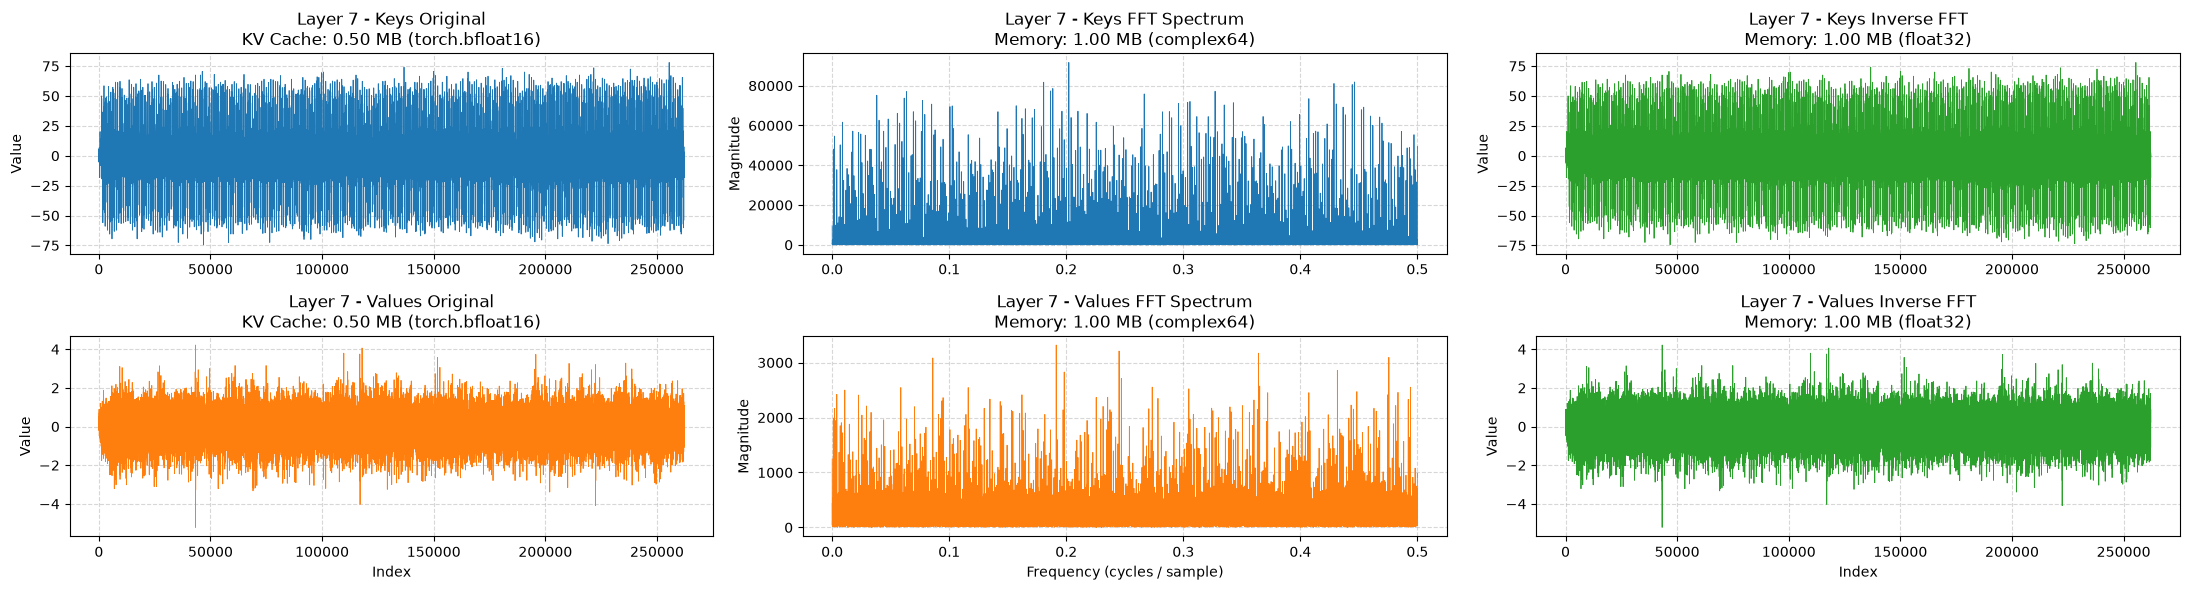

[Layer 14 Keys  ] len=262144  rfft bins=131073  DC=32002.90  IFFT max err=3.34e-06
    bin   57344  freq 0.218750  (period       4.6 samples)  |X|=38417.55
    bin   90112  freq 0.343750  (period       2.9 samples)  |X|=37471.98
    bin   40960  freq 0.156250  (period       6.4 samples)  |X|=35052.72
    bin   61440  freq 0.234375  (period       4.3 samples)  |X|=34366.82
    bin  120832  freq 0.460938  (period       2.2 samples)  |X|=34194.55
[Layer 14 Values] len=262144  rfft bins=131073  DC=1170.44  IFFT max err=3.81e-06
    bin   59904  freq 0.228516  (period       4.4 samples)  |X|=7334.29
    bin   87040  freq 0.332031  (period       3.0 samples)  |X|=6723.60
    bin  125440  freq 0.478516  (period       2.1 samples)  |X|=6721.18
    bin   87552  freq 0.333984  (period       3.0 samples)  |X|=6696.81
    bin   68864  freq 0.262695  (period       3.8 samples)  |X|=6670.92


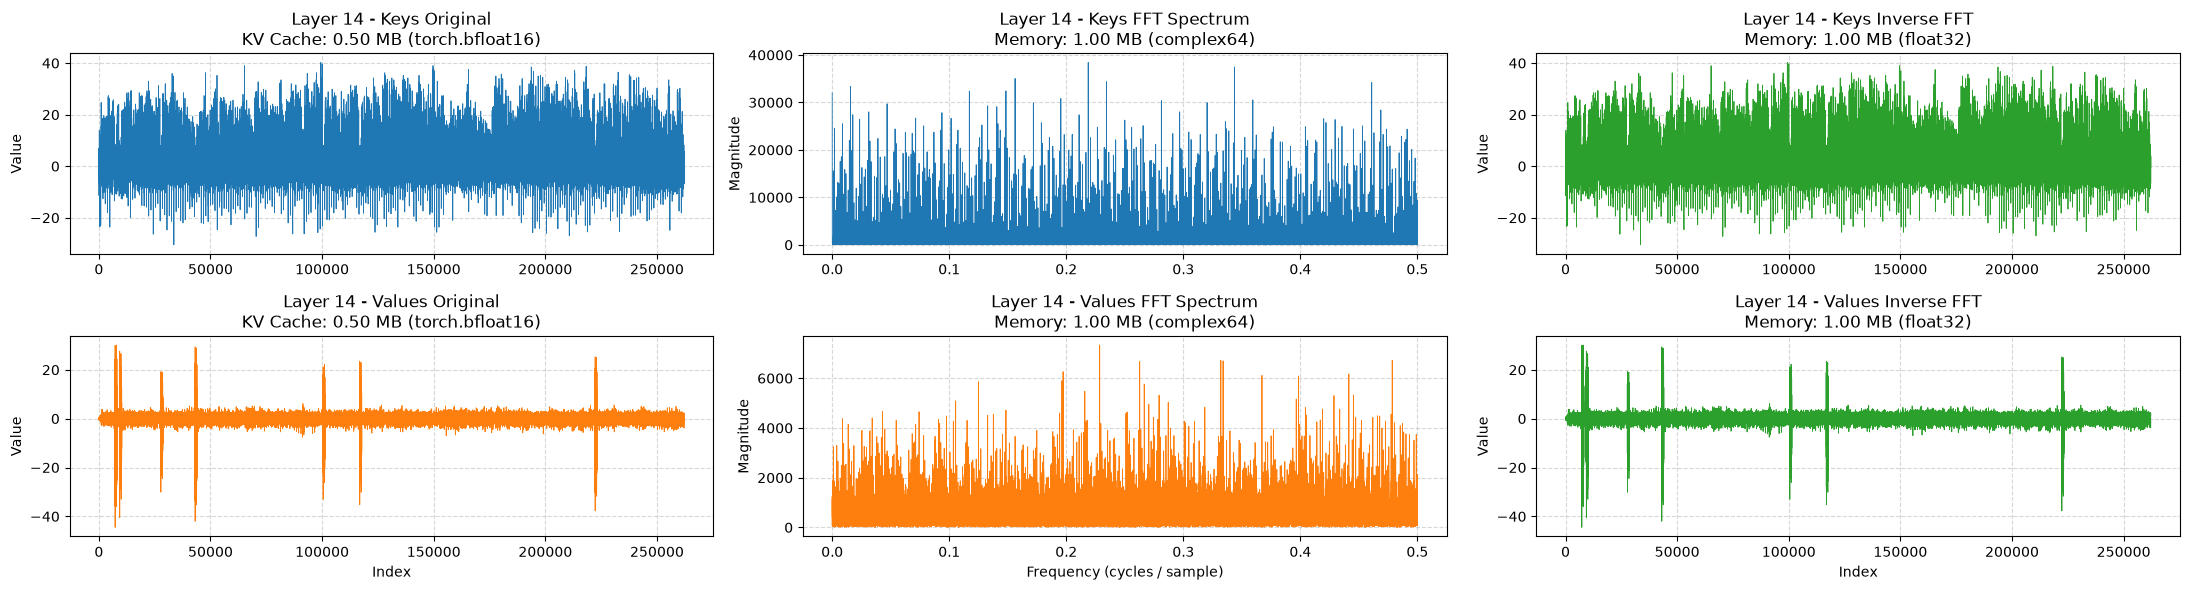

[Layer 27 Keys  ] len=262144  rfft bins=131073  DC=13261.86  IFFT max err=5.72e-06
    bin   47360  freq 0.180664  (period       5.5 samples)  |X|=41515.33
    bin    9984  freq 0.038086  (period      26.3 samples)  |X|=40866.16
    bin   51456  freq 0.196289  (period       5.1 samples)  |X|=37611.14
    bin   28928  freq 0.110352  (period       9.1 samples)  |X|=37150.81
    bin   40704  freq 0.155273  (period       6.4 samples)  |X|=36824.88
[Layer 27 Values] len=262144  rfft bins=131073  DC=9097.65  IFFT max err=7.63e-06
    bin   27904  freq 0.106445  (period       9.4 samples)  |X|=84633.12
    bin  123392  freq 0.470703  (period       2.1 samples)  |X|=83732.18
    bin  110848  freq 0.422852  (period       2.4 samples)  |X|=83282.32
    bin   87552  freq 0.333984  (period       3.0 samples)  |X|=82616.43
    bin   88320  freq 0.336914  (period       3.0 samples)  |X|=80894.88


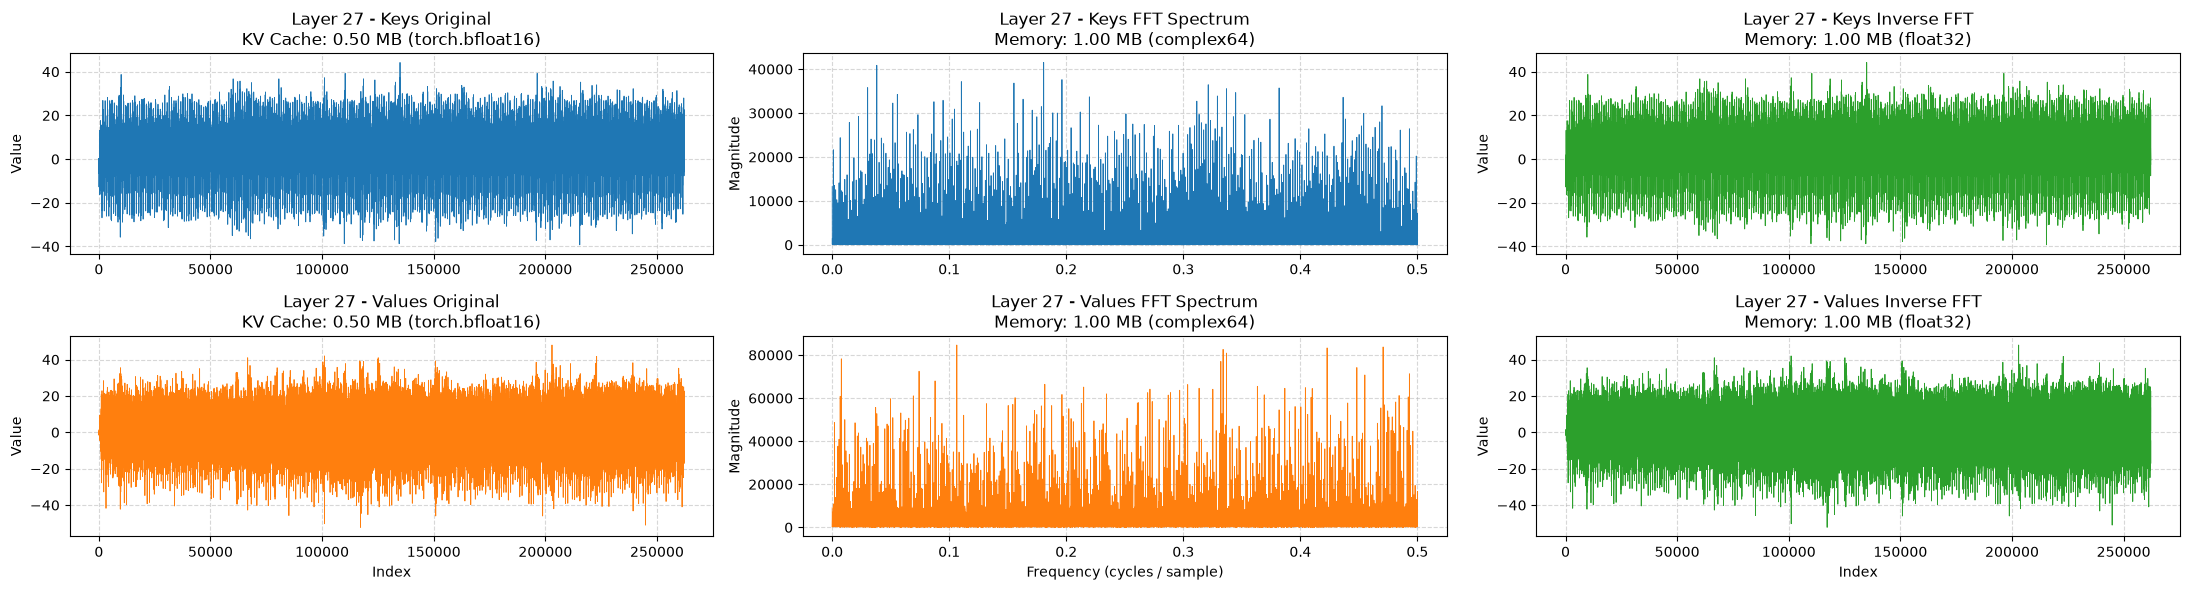

In [5]:
# Flatten each layer's K/V cache to 1D in (batch, seq, heads, head_dim) order, then FFT
import numpy as np
from transformers import DynamicCache

probe_layers = [0, info["layers"] // 4, info["layers"] // 2, info["layers"] - 1]
PLOT_LAYERS = probe_layers          
TOP_N = 5                           # number of peaks to print

cache = DynamicCache(config=model.config)
with torch.no_grad():
    tools.forward_logits(model, val_batches[0][:1], cache)
print("cache:", tuple(cache.layers[0].keys.shape), "(batch, heads, seq, head_dim)\n")

for i in PLOT_LAYERS:
    fig, axes = plt.subplots(2, 3, figsize=(22, 6))
    for row, (name, tensor, color) in enumerate((("Keys", cache.layers[i].keys, "tab:blue"),
                                                 ("Values", cache.layers[i].values, "tab:orange"))):
        cache_mem = tensor.numel() * tensor.element_size() / 1024**2

        # 1. flatten
        x = tensor.permute(0, 2, 1, 3).detach().cpu().float().numpy().flatten()

        # 2. FFT / 3. IFFT
        spec = np.fft.rfft(x)
        mag = np.abs(spec)
        freqs = np.fft.rfftfreq(len(x))
        recon = np.fft.irfft(spec, n=len(x))

        axes[row, 0].plot(x, lw=0.6, color=color)
        axes[row, 0].set_title(f"Layer {i} - {name} Original\n"
                               f"KV Cache: {cache_mem:.2f} MB ({tensor.dtype})")
        axes[row, 1].plot(freqs, mag, lw=0.6, color=color)
        axes[row, 1].set_title(f"Layer {i} - {name} FFT Spectrum\n"
                               f"Memory: {spec.nbytes / 1024**2:.2f} MB ({spec.dtype})")
        axes[row, 2].plot(recon, lw=0.6, color="tab:green")
        axes[row, 2].set_title(f"Layer {i} - {name} Inverse FFT\n"
                               f"Memory: {recon.nbytes / 1024**2:.2f} MB ({recon.dtype})")
        axes[row, 0].set_ylabel("Value")
        axes[row, 1].set_ylabel("Magnitude")
        axes[row, 2].set_ylabel("Value")

        # print frequency peaks
        top = np.argsort(mag[1:])[::-1][:TOP_N] + 1   # top peaks excluding DC
        print(f"[Layer {i:>2} {name:<6}] len={len(x)}  rfft bins={len(spec)}  "
              f"DC={mag[0]:.2f}  IFFT max err={np.abs(recon - x).max():.2e}")
        for b in top:
            period = 1 / freqs[b]
            print(f"    bin {b:>7}  freq {freqs[b]:.6f}  (period {period:9.1f} samples)  "
                  f"|X|={mag[b]:.2f}")

    for a in axes[1]:
        a.set_xlabel("Index")
    axes[1, 1].set_xlabel("Frequency (cycles / sample)")
    for a in axes.flat:
        a.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

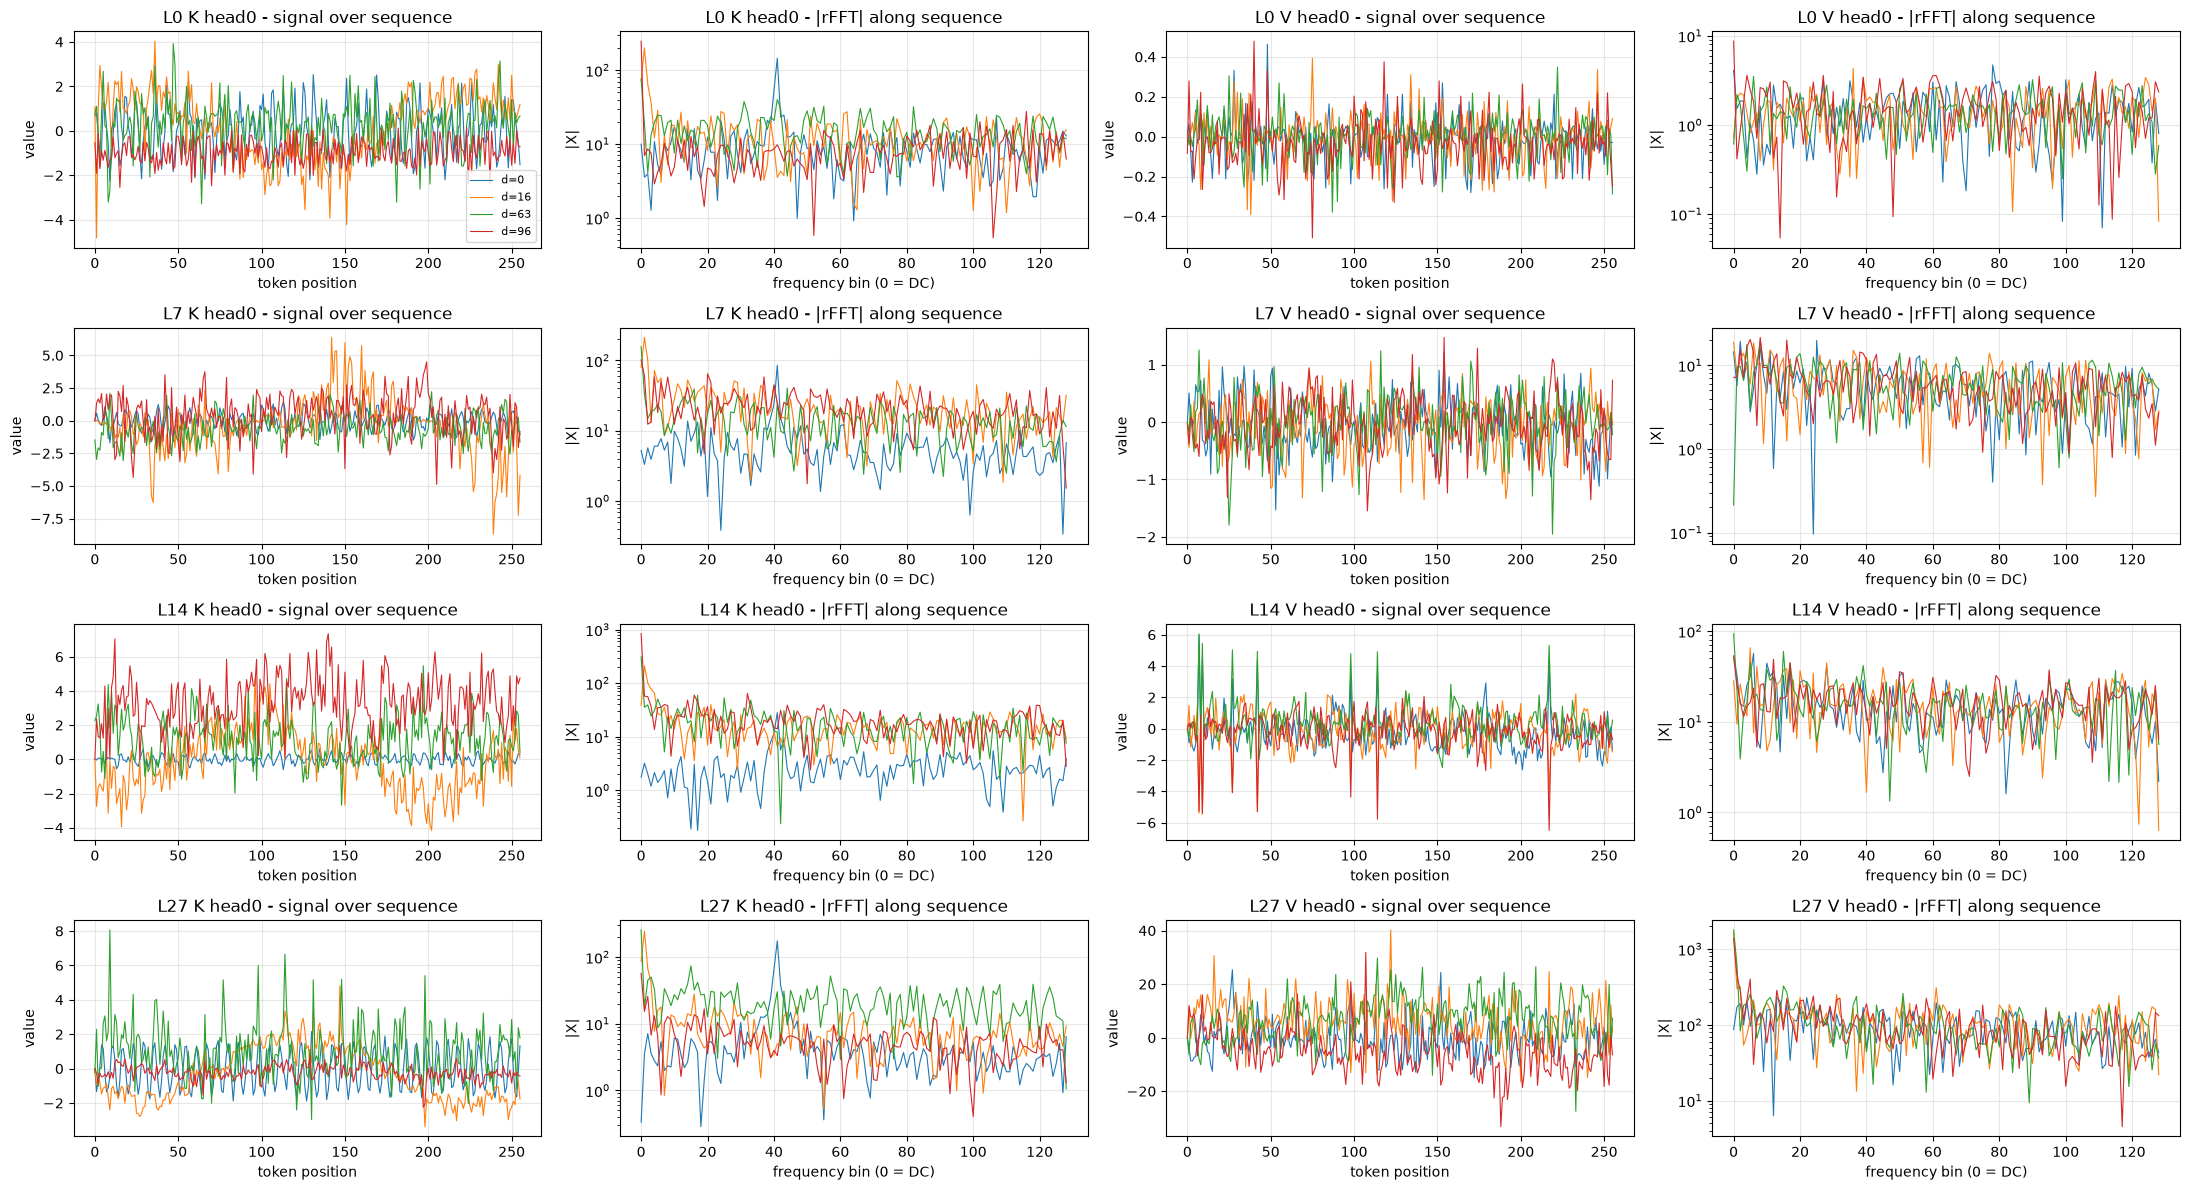

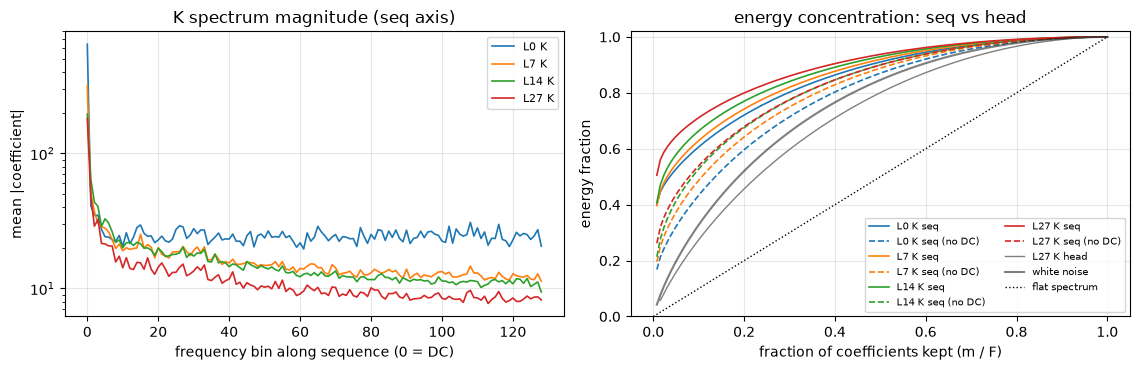

                F         K mean (min, max)         V mean (min, max)
        head   65      0.790 (0.638, 0.841)      0.839 (0.832, 0.841)
         seq  129      0.925 (0.903, 0.941)      0.877 (0.850, 0.905)
 seq (no DC)  128      0.893 (0.870, 0.909)      0.861 (0.846, 0.885)


In [6]:
SIG_HEAD = 0
SIG_CHANNELS = (0, 16, 63, 96)
fig, axes = plt.subplots(len(probe_layers), 4, figsize=(22, 3 * len(probe_layers)))
for r, layer in enumerate(probe_layers):
    for c, (name, tensor) in enumerate((("K", cache.layers[layer].keys),
                                        ("V", cache.layers[layer].values))):
        sig = tensor[0, SIG_HEAD].detach().cpu().float()          # (S, D)
        spec = torch.fft.rfft(sig, dim=0).abs()                   # (S//2+1, D)
        ax_sig, ax_fft = axes[r, 2 * c], axes[r, 2 * c + 1]
        for d in SIG_CHANNELS:
            ax_sig.plot(sig[:, d], lw=0.8, label=f"d={d}")
            ax_fft.plot(spec[:, d], lw=0.8, label=f"d={d}")
        ax_sig.set(title=f"L{layer} {name} head{SIG_HEAD} - signal over sequence",
                   xlabel="token position", ylabel="value")
        ax_fft.set(title=f"L{layer} {name} head{SIG_HEAD} - |rFFT| along sequence",
                   xlabel="frequency bin (0 = DC)", ylabel="|X|", yscale="log")
for a in axes.flat:
    a.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- all-layer statistics
stats = tools.spectrum_stats(model, val_batches[0])               # head axis (for comparison)
stats_seq = tools.spectrum_stats(model, val_batches[0], axis="seq")
stats_seq_ac = tools.spectrum_stats(model, val_batches[0], axis="seq", drop_dc=True)
variants = {"head": stats, "seq": stats_seq, "seq (no DC)": stats_seq_ac}

fig, (ax_mag, ax_cum) = plt.subplots(1, 2, figsize=(11.5, 3.8))
for layer in probe_layers:
    line, = ax_mag.plot(stats_seq["mean_mag"][(layer, "k")], label=f"L{layer} K", lw=1.2)
    for name, style in (("seq", "-"), ("seq (no DC)", "--")):
        st = variants[name]
        x = torch.arange(1, st["n_freq"] + 1) / st["n_freq"]
        ax_cum.plot(x, st["energy_curve"][(layer, "k")], style, color=line.get_color(),
                    lw=1.2, label=f"L{layer} K {name}")
x = torch.arange(1, stats["n_freq"] + 1) / stats["n_freq"]
ax_cum.plot(x, stats["energy_curve"][(probe_layers[-1], "k")], color="gray", lw=1,
            label=f"L{probe_layers[-1]} K head")
# Baseline: white noise. Sorting by magnitude per sample means even structureless noise keeps ~0.84 of the energy in half the coefficients (dotted line: all coefficients equal in magnitude)
noise = torch.fft.rfft(torch.randn(4096, val_batches[0].shape[-1]), dim=-1).abs().pow(2)
noise = noise.sort(dim=-1, descending=True).values
noise_curve = (noise.cumsum(-1) / noise.sum(-1, keepdim=True)).mean(0)
x = torch.arange(1, noise_curve.numel() + 1) / noise_curve.numel()
ax_cum.plot(x, noise_curve, "k", lw=1.5, alpha=0.5, label="white noise")
ax_cum.plot([0, 1], [0, 1], "k:", lw=1, label="flat spectrum")
ax_mag.set(xlabel="frequency bin along sequence (0 = DC)", ylabel="mean |coefficient|",
           title="K spectrum magnitude (seq axis)", yscale="log")
ax_cum.set(xlabel="fraction of coefficients kept (m / F)", ylabel="energy fraction",
           title="energy concentration: seq vs head", ylim=(0, 1.02))
for a in (ax_mag, ax_cum):
    a.grid(alpha=0.3)
ax_mag.legend(fontsize=8)
ax_cum.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

# Energy kept when retaining half the coefficients. Layer mean (min, max)
print(f"{'':>12} {'F':>4}  {'K mean (min, max)':>24}  {'V mean (min, max)':>24}")
for name, st in variants.items():
    half = st["n_freq"] // 2
    cells = []
    for which in ("k", "v"):
        kept = [float(st["energy_curve"][(l, which)][half - 1]) for l in range(info["layers"])]
        cells.append(f"{sum(kept)/len(kept):.3f} ({min(kept):.3f}, {max(kept):.3f})")
    print(f"{name:>12} {st['n_freq']:>4}  {cells[0]:>24}  {cells[1]:>24}")
half = noise_curve.numel() // 2

# Saved for the README chart: per-layer energy kept by half the coefficients + white-noise reference
summary["spectrum_half_energy"] = {
    name: {w: [float(st["energy_curve"][(l, w)][st["n_freq"] // 2 - 1]) for l in range(info["layers"])]
           for w in ("k", "v")}
    for name, st in variants.items()
}
summary["spectrum_half_energy"]["white_noise"] = float(noise_curve[half - 1])


In [7]:
compressor = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
print("selector params:", sum(p.numel() for p in compressor.parameters()),
      f"({sum(p.numel() for p in compressor.parameters())/sum(p.numel() for p in model.parameters()):.2%} of base model)")

baseline_rows = tools.sweep_ratios(
    model, compressor, val_batches,
    ratios=(1.0, 0.9375, 0.875, 0.75, 0.5, 0.25),
    modes=("energy", "lowpass", "random"),
)
summary["untrained_truncation"] = [
    {k: r[k] for k in ("mode", "keep_ratio", "kl", "agree", "ppl", "ppl_teacher")}
    for r in baseline_rows
]

selector params: 2784824 (0.47% of base model)
  energy keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
  energy keep=0.9375  kl=   2.8235 agree=0.227 ppl=      504.00
  energy keep=0.875   kl=   4.0510 agree=0.135 ppl=     1728.34
  energy keep=0.75    kl=   5.6512 agree=0.070 ppl=     8511.84
  energy keep=0.5     kl=   9.3800 agree=0.022 ppl=   323562.17
  energy keep=0.25    kl=  10.6556 agree=0.006 ppl=  1007824.26
 lowpass keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
 lowpass keep=0.9375  kl=   1.8198 agree=0.347 ppl=      198.80
 lowpass keep=0.875   kl=   3.5322 agree=0.180 ppl=     1044.87
 lowpass keep=0.75    kl=   7.0741 agree=0.061 ppl=    33717.72
 lowpass keep=0.5     kl=   9.6242 agree=0.008 ppl=   354818.86
 lowpass keep=0.25    kl=  11.9881 agree=0.001 ppl=  3241240.59
  random keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
  random keep=0.9375  kl=   5.9304 agree=0.073 ppl=    10266.47
  random keep=0.875   kl=   7.0395 agree=0.054 ppl=    29

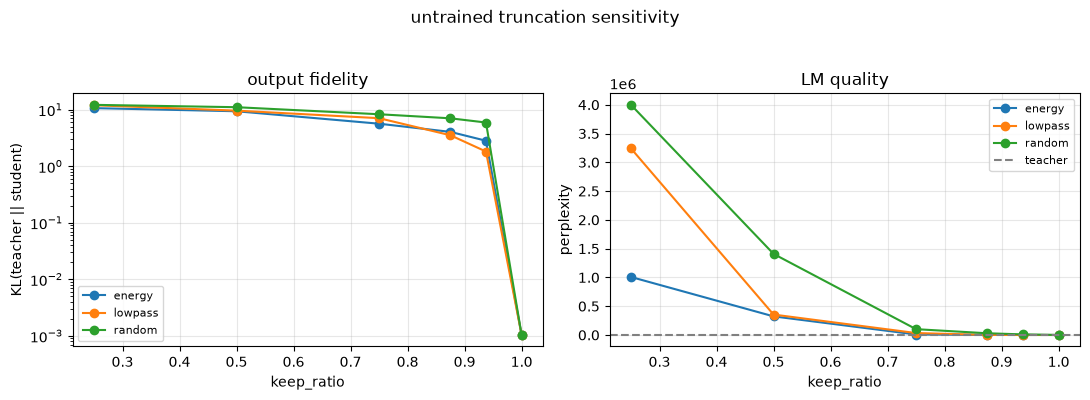

In [8]:
tools.plot_tradeoff(baseline_rows)
plt.suptitle("untrained truncation sensitivity", y=1.04)
plt.tight_layout()
plt.show()

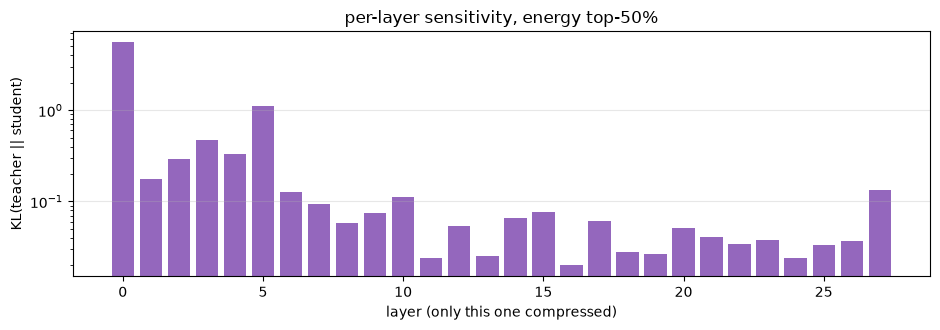

5 most sensitive layers: [(0, 5.5229), (5, 1.1232), (3, 0.4671), (4, 0.3291), (2, 0.291)]
5 least sensitive layers: [(19, 0.0268), (13, 0.0252), (11, 0.0243), (24, 0.0238), (16, 0.02)]


In [9]:
sens = tools.layer_sensitivity(model, compressor, val_batches[:2], keep_ratio=0.5, mode="energy")
summary["layer_sensitivity"] = sens

fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.bar([r["layer"] for r in sens], [r["kl"] for r in sens], color="tab:purple")
ax.set(xlabel="layer (only this one compressed)", ylabel="KL(teacher || student)",
       title="per-layer sensitivity, energy top-50%", yscale="log")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

ranked = sorted(sens, key=lambda r: -r["kl"])
print("5 most sensitive layers:", [(r["layer"], round(r["kl"], 4)) for r in ranked[:5]])
print("5 least sensitive layers:", [(r["layer"], round(r["kl"], 4)) for r in ranked[-5:]])

## 3. Selector and cache sanity check

Checks before training

1. With `mode="off"`, check the compressed-cache output matches the original bit for bit
2. Check the initial mask is close to 1
3. rFFT→irFFT round-trip error with the mask all 1 (measurement baseline)

In [ ]:
# 1) 
off = tools.evaluate(model, compressor, val_batches[:2], mode="off")
print(f"off      : KL={off['kl']:.3e}  agree={off['agree']:.4f}")

# 3) baseline check
full = tools.evaluate(model, compressor, val_batches[:2], mode="topk", keep_ratio=1.0)
print(f"keep 100%: KL={full['kl']:.3e}  agree={full['agree']:.4f}")

# 2) initial mask. FreqSelector's last Linear starts with weight=0, bias=init_logit
init = tools.evaluate(model, compressor, val_batches[:2], mode="soft")
print(f"soft@init: KL={init['kl']:.3e}  agree={init['agree']:.4f}  usage={init['usage']:.4f}")
summary["sanity"] = {"off_kl": off["kl"], "roundtrip_kl": full["kl"],
                     "soft_init_kl": init["kl"], "soft_init_usage": init["usage"]}

off      : KL=0.000e+00  agree=1.0000   <- 0 / 1.0 expected
keep 100%: KL=1.032e-03  agree=0.9824   <- fft round trip + bf16 rounding
soft@init: KL=2.536e-03  agree=0.9648  usage=0.9820


## 4. Stage 1 — soft mask training

loss function

$$L = L_{KD} + \lambda_{sparse}\,\overline{mask} + \lambda_{budget}\,\mathrm{relu}(\overline{mask} - r_{target})^2$$

- `train_selectors`: ramps the sparsity/budget coefficients linearly from 0 over the first `warmup` steps
- Reason: the initial mask is near 1, so the budget-term gradient is large
- Without the ramp the selector fails to converge on the first step (KL 0.003 → 1.2)

In [11]:
TARGET_RATIO = 0.5

tools.set_seed(0)
compressor_soft = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
history = tools.train_selectors(
    model, compressor_soft, train_batches,
    epochs=EPOCHS, lr=LR,
    mode="soft",
    lambda_sparse=0.01,
    target_ratio=TARGET_RATIO,
    lambda_budget=5.0,
    warmup=20,
    log_every=max(1, len(train_batches) // 4),
)
torch.save(compressor_soft.state_dict(), RESULTS / "selectors" / "stage1_soft.pt")
print("peak GPU MiB:", torch.cuda.max_memory_allocated() / 2**20)

step    0  loss 0.06193  KL 0.00336  usage 0.982
step   22  loss 1.04474  KL 0.02185  usage 0.950
step   44  loss 0.80832  KL 0.17009  usage 0.855
step   66  loss 0.64773  KL 0.25182  usage 0.779
step   88  loss 0.40824  KL 0.19239  usage 0.704
step  110  loss 0.41190  KL 0.24736  usage 0.678
step  132  loss 0.32587  KL 0.18010  usage 0.667
step  154  loss 0.31592  KL 0.19554  usage 0.651
step  176  loss 0.29668  KL 0.18445  usage 0.645
step  198  loss 0.27576  KL 0.17513  usage 0.637
step  220  loss 0.27784  KL 0.18058  usage 0.635
step  242  loss 0.25261  KL 0.17454  usage 0.620
step  264  loss 0.26162  KL 0.18339  usage 0.620
peak GPU MiB: 4889.58642578125


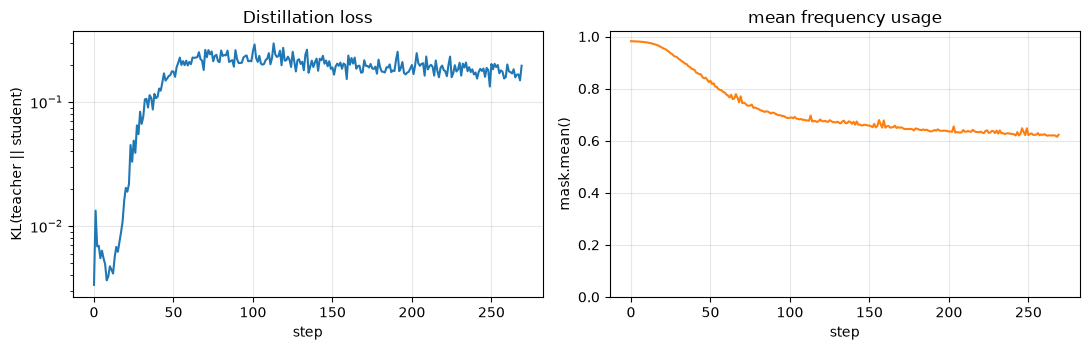

In [12]:
tools.plot_training(history)
plt.tight_layout()
plt.show()

soft mask: usage=0.618  KL=0.1982  agree=0.751  ppl=40.27 (teacher 36.46)


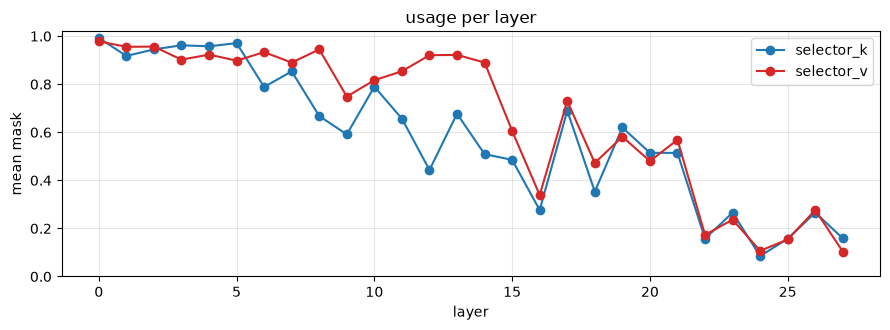

In [13]:
soft = tools.evaluate(model, compressor_soft, val_batches, mode="soft")
print(f"soft mask: usage={soft['usage']:.3f}  KL={soft['kl']:.4f}  "
      f"agree={soft['agree']:.3f}  ppl={soft['ppl']:.2f} (teacher {soft['ppl_teacher']:.2f})")
summary["stage1_soft"] = {k: soft[k] for k in ("kl", "agree", "ppl", "ppl_teacher", "usage")}

tools.plot_layer_usage(soft["usage_by_layer"])
plt.tight_layout()
plt.show()

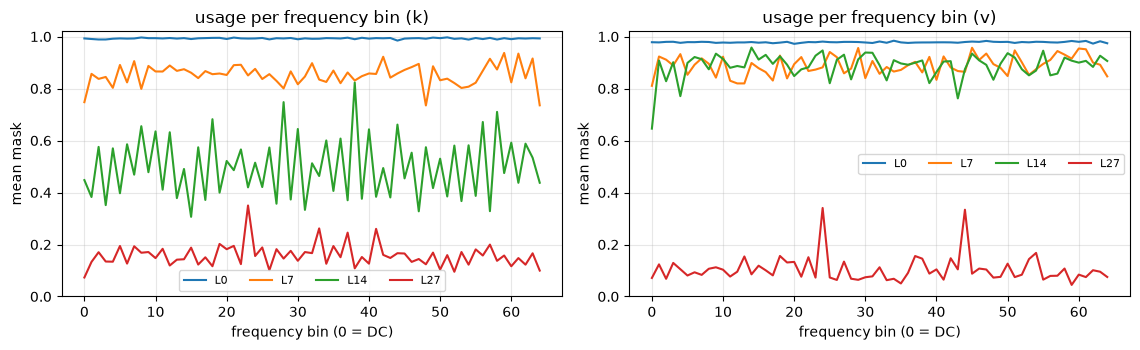

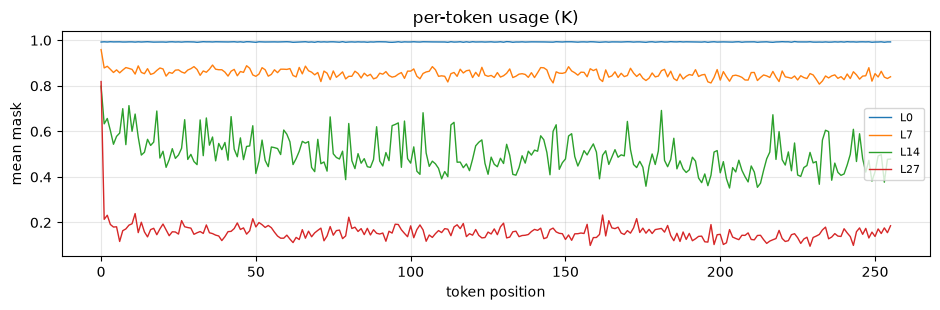

In [ ]:
# selector frequencies. Per-layer pattern comparison
compressor_soft.reset_log()
compressor_soft.mode, compressor_soft.collect = "soft", True
with torch.no_grad():
    cache = FFTCompressedCache(compressor_soft, config=model.config)
    tools.forward_logits(model, val_batches[0], cache)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
tools.plot_freq_profile(compressor_soft, probe_layers, "k", ax=axes[0])
tools.plot_freq_profile(compressor_soft, probe_layers, "v", ax=axes[1])
plt.tight_layout()
plt.show()

# Check by token position / check whether it behaves adaptively
fig, ax = plt.subplots(figsize=(9.5, 3.2))
for layer in probe_layers:
    ax.plot(compressor_soft.per_token_usage(layer, "k"), lw=1, label=f"L{layer}")
ax.set(xlabel="token position", ylabel="mean mask", title="per-token usage (K)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
del cache

### soft -> hard gap

- Effect of the soft mask: shrinks magnitude (does not remove)
- Cache savings need a 0/1 selection
- Check by cutting the trained soft selector scores directly with top-k

    topk keep=1.0     kl=   0.0010 agree=0.979 ppl=       36.47
    topk keep=0.875   kl=   5.4159 agree=0.101 ppl=     6551.23
    topk keep=0.75    kl=   8.2329 agree=0.035 ppl=    99281.13
    topk keep=0.5     kl=   9.6439 agree=0.017 ppl=   378337.92
    topk keep=0.25    kl=   8.5044 agree=0.013 ppl=   113242.34
  energy keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
  energy keep=0.875   kl=   4.0510 agree=0.135 ppl=     1728.34
  energy keep=0.75    kl=   5.6512 agree=0.070 ppl=     8511.84
  energy keep=0.5     kl=   9.3800 agree=0.022 ppl=   323562.17
  energy keep=0.25    kl=  10.6556 agree=0.006 ppl=  1007824.26
 lowpass keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
 lowpass keep=0.875   kl=   3.5322 agree=0.180 ppl=     1044.87
 lowpass keep=0.75    kl=   7.0741 agree=0.061 ppl=    33717.72
 lowpass keep=0.5     kl=   9.6242 agree=0.008 ppl=   354818.86
 lowpass keep=0.25    kl=  11.9881 agree=0.001 ppl=  3241240.59


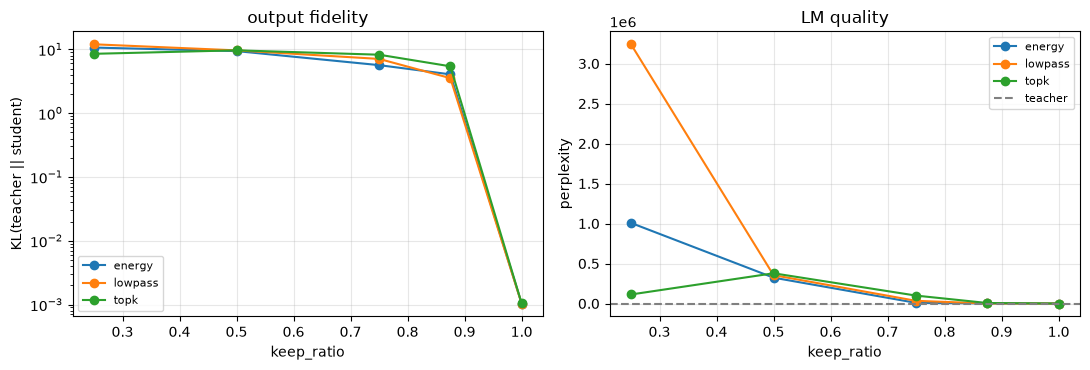

In [15]:
gap_rows = tools.sweep_ratios(
    model, compressor_soft, val_batches,
    ratios=(1.0, 0.875, 0.75, 0.5, 0.25),
    modes=("topk", "energy", "lowpass"),
)
summary["stage1_to_hard"] = [
    {k: r[k] for k in ("mode", "keep_ratio", "kl", "agree", "ppl")} for r in gap_rows
]
tools.plot_tradeoff(gap_rows)
plt.tight_layout()
plt.show()

## 5. Stage 2 — hard selection training

- Train with a 0/1 mask from the start instead of cutting the soft selector afterwards
- `straight_through=True`: forward uses the hard mask, backward the sigmoid gradient → yields a gradient that passes through top-k selection
- The keep ratio is fixed by top-k, so the sparsity/budget terms are disabled (`lambda_sparse=0, target_ratio=None`)
- The loss is the distillation loss alone; what is learned is frequency selection within the fixed budget

In [16]:
RATIOS = (0.9375, 0.875, 0.75, 0.5) if not QUICK else (0.875, 0.5)

stage2 = {}
rows_learned = []
for ratio in RATIOS:
    tools.set_seed(0)
    comp = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
    print(f"\n=== keep_ratio {ratio} ===")
    tools.train_selectors(
        model, comp, train_batches,
        epochs=EPOCHS, lr=LR,
        mode="topk", keep_ratio=ratio, straight_through=True,
        lambda_sparse=0.0, target_ratio=None,
        log_every=max(1, len(train_batches) // 2),
    )
    row = tools.evaluate(model, comp, val_batches, mode="topk", keep_ratio=ratio,
                         collect_usage=False)
    row.pop("usage_by_layer", None)
    row["mode"] = "topk (learned, STE)"
    rows_learned.append(row)
    stage2[ratio] = comp
    torch.save(comp.state_dict(), RESULTS / "selectors" / f"stage2_topk_{ratio}.pt")
    print(f"-> KL={row['kl']:.4f} agree={row['agree']:.3f} ppl={row['ppl']:.2f}")


=== keep_ratio 0.9375 ===
step    0  loss 1.73666  KL 1.73666  usage 0.938
step   45  loss 1.89392  KL 1.89392  usage 0.938
step   90  loss 1.54144  KL 1.54144  usage 0.938
step  135  loss 1.65711  KL 1.65711  usage 0.938
step  180  loss 1.92087  KL 1.92087  usage 0.938
step  225  loss 1.90690  KL 1.90690  usage 0.938
-> KL=1.7503 agree=0.344 ppl=157.79

=== keep_ratio 0.875 ===
step    0  loss 3.54492  KL 3.54492  usage 0.877
step   45  loss 2.28143  KL 2.28143  usage 0.877
step   90  loss 2.68320  KL 2.68320  usage 0.877
step  135  loss 2.53685  KL 2.53685  usage 0.877
step  180  loss 2.54822  KL 2.54822  usage 0.877
step  225  loss 2.49400  KL 2.49400  usage 0.877
-> KL=2.4885 agree=0.248 ppl=302.04

=== keep_ratio 0.75 ===
step    0  loss 6.58765  KL 6.58765  usage 0.754
step   45  loss 3.57251  KL 3.57251  usage 0.754
step   90  loss 3.19287  KL 3.19287  usage 0.754
step  135  loss 2.93029  KL 2.93029  usage 0.754
step  180  loss 3.11241  KL 3.11241  usage 0.754
step  225  loss 2

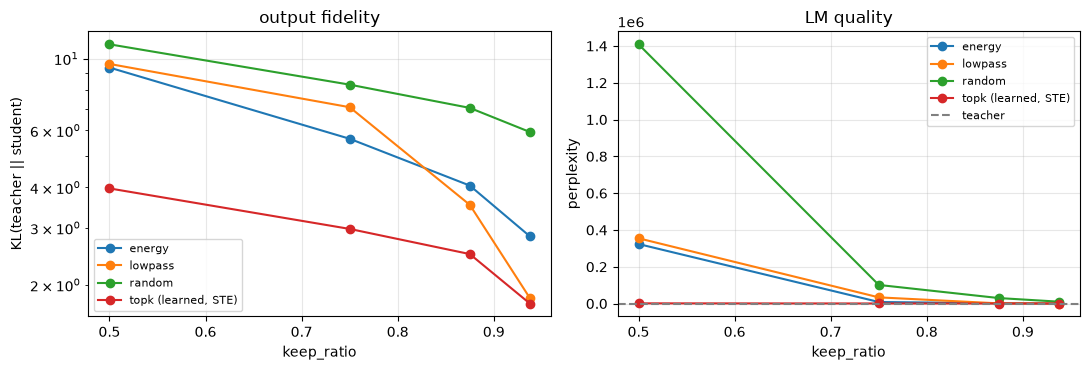

   keep  learned KL   energy KL  lowpass KL   random KL
 0.9375      1.7503      2.8235      1.8198      5.9304
  0.875      2.4885      4.0510      3.5322      7.0395
   0.75      2.9760      5.6512      7.0741      8.3057
    0.5      3.9702      9.3800      9.6242     11.0672


In [ ]:
# Train and check against the baselines
rows_ref = [r for r in baseline_rows if r["keep_ratio"] in RATIOS]
trade_rows = rows_learned + rows_ref
summary["stage2"] = [{k: r[k] for k in ("mode", "keep_ratio", "kl", "agree", "ppl", "ppl_teacher")}
                     for r in trade_rows]

tools.plot_tradeoff(trade_rows)
plt.tight_layout()
plt.show()

print(f"{'keep':>7} {'learned KL':>11} {'energy KL':>11} {'lowpass KL':>11} {'random KL':>11}")
for ratio in RATIOS:
    def pick(mode):
        hit = [r for r in trade_rows if r["mode"] == mode and r["keep_ratio"] == ratio]
        return f"{hit[0]['kl']:.4f}" if hit else "-"
    print(f"{ratio:>7} {pick('topk (learned, STE)'):>11} {pick('energy'):>11} "
          f"{pick('lowpass'):>11} {pick('random'):>11}")

## 6. Trying a different allocation per layer

- Applies the per-layer sensitivity from Section 2
- Exclude the first N layers from compression; compress only the insensitive layers
- Check usage and quality per skip count

In [ ]:
SKIPS = (0, 2, 4, 8, 12) if not QUICK else (0, 4)
KEEP = 0.5

skip_rows = []
for skip in SKIPS:
    compressor.active_layers = set(range(skip, info["layers"]))
    r = tools.evaluate(model, compressor, val_batches, mode="energy", keep_ratio=KEEP,
                       collect_usage=False)
    # mean usage
    compressed = info["layers"] - skip
    r["effective_keep"] = (compressed * KEEP + skip * 1.0) / info["layers"]
    r["skip"] = skip
    skip_rows.append(r)
    print(f"skip={skip:>2} ({compressed} layers @ keep {KEEP}) "
          f"-> usage {r['effective_keep']:.3f}  KL={r['kl']:.4f}  ppl={r['ppl']:.2f}")
compressor.active_layers = set(range(info["layers"]))
summary["layer_budget"] = [{k: r[k] for k in ("skip", "effective_keep", "kl", "agree", "ppl")}
                           for r in skip_rows]

skip= 0 (28 layers @ keep 0.5) -> effective usage 0.500  KL=9.3800  ppl=323562.17
skip= 2 (26 layers @ keep 0.5) -> effective usage 0.536  KL=5.6522  ppl=9368.67
skip= 4 (24 layers @ keep 0.5) -> effective usage 0.571  KL=4.7382  ppl=3900.34
skip= 8 (20 layers @ keep 0.5) -> effective usage 0.643  KL=1.8579  ppl=228.22
skip=12 (16 layers @ keep 0.5) -> effective usage 0.714  KL=1.0848  ppl=107.55


In [19]:
# Retrain with the best skip value (layer selection + training)
best_skip = min(skip_rows, key=lambda r: r["kl"])["skip"]
print("best skip:", best_skip)

tools.set_seed(0)
comp_skip = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
comp_skip.active_layers = set(range(best_skip, info["layers"]))
tools.train_selectors(
    model, comp_skip, train_batches,
    epochs=EPOCHS, lr=LR,
    mode="topk", keep_ratio=KEEP, straight_through=True,
    lambda_sparse=0.0, target_ratio=None,
    log_every=max(1, len(train_batches) // 2),
)
best = tools.evaluate(model, comp_skip, val_batches, mode="topk", keep_ratio=KEEP,
                      collect_usage=False)
print(f"skip={best_skip} + training: KL={best['kl']:.4f} agree={best['agree']:.3f} "
      f"ppl={best['ppl']:.2f} (teacher {best['ppl_teacher']:.2f})")
torch.save(comp_skip.state_dict(), RESULTS / "selectors" / f"stage3_skip{best_skip}_keep{KEEP}.pt")
summary["layer_budget_trained"] = {"skip": best_skip, "keep": KEEP,
                                   **{k: best[k] for k in ("kl", "agree", "ppl", "ppl_teacher")}}

best skip: 12
step    0  loss 1.53063  KL 1.53063  usage 0.492


step   45  loss 0.50408  KL 0.50408  usage 0.492
step   90  loss 0.44965  KL 0.44965  usage 0.492
step  135  loss 0.39853  KL 0.39853  usage 0.492
step  180  loss 0.39232  KL 0.39232  usage 0.492
step  225  loss 0.38744  KL 0.38744  usage 0.492
skip=12 + training: KL=0.4313 agree=0.634 ppl=49.10 (teacher 36.46)


## 7. Stage 3 — actual KV cache compression

- `FFTCompressedCache` up to Section 6: stores the reconstructed D-dim real vectors → only information content drops, bytes unchanged
- Actual compression needs storing only the frequency indices and complex coefficients
- `SparseSpectralCache`: stores the top `keep` coefficients per token and head in the format below; only on hand-off to attention, scatter into a zero-filled spectrum and irFFT

```
idx  : int16        (B, H, S, keep)
re   : bfloat16     (B, H, S, keep)
im   : bfloat16     (B, H, S, keep)
```

Overhead
- One coefficient = real + imaginary part, 4 bytes = two bf16 slots of the original
- `D/2+1` rFFT coefficients → keeping half the coefficients is practically the same size as the original
- The selected frequency positions must be stored separately too

In [20]:
seq = SEQ_LEN
print(f"seq_len={seq}, {info['layers']} layers, {info['kv_heads']} kv heads, head_dim={info['head_dim']}\n")
dense = tools.dense_kv_bytes(info, seq)
print(f"{'keep':>5} {'ratio':>7} {'bitmask':>12} {'vs dense':>9} {'index':>12} {'vs dense':>9}")
mem_rows = []
for keep in (65, 48, 32, 24, 16, 8, 4):
    keep = min(keep, info["n_freq"])
    bm = tools.spectral_kv_bytes(info, seq, keep, index_scheme="bitmask")
    ix = tools.spectral_kv_bytes(info, seq, keep, index_scheme="index")
    mem_rows.append({"keep": keep, "ratio": keep / info["n_freq"],
                     "bitmask": bm, "index": ix, "dense": dense})
    print(f"{keep:>5} {keep/info['n_freq']:>7.3f} {bm/2**20:>10.2f}MB {bm/dense:>8.2f}x "
          f"{ix/2**20:>10.2f}MB {ix/dense:>8.2f}x")
print(f"\ndense: {dense/2**20:.2f}MB")
summary["memory_table"] = mem_rows

seq_len=256, 28 layers, 8 kv heads, head_dim=128

 keep   ratio      bitmask  vs dense        index  vs dense
   65   1.000      29.42MB     1.05x      42.66MB     1.52x
   48   0.738      21.98MB     0.79x      31.50MB     1.12x
   32   0.492      14.98MB     0.54x      21.00MB     0.75x
   24   0.369      11.48MB     0.41x      15.75MB     0.56x
   16   0.246       7.98MB     0.29x      10.50MB     0.38x
    8   0.123       4.48MB     0.16x       5.25MB     0.19x
    4   0.062       2.73MB     0.10x       2.62MB     0.09x

dense: 28.00MB


In [ ]:
# Decode with the real cache. Computation runs directly on the tensors the cache allocated
PROMPT = "Explain in two sentences why the sky is blue."
KEEP_N = 32

ref = tools.greedy_generate(model, tok, PROMPT, max_new_tokens=48)
print(f"[original]  {ref['tok_per_s']:.1f} tok/s\n{ref['text']!r}\n")

for comp_name, comp_obj in (("untrained", compressor), (f"trained skip{best_skip}", comp_skip)):
    out = tools.greedy_generate(
        model, tok, PROMPT, max_new_tokens=48,
        make_cache=lambda c=comp_obj: SparseSpectralCache(c, keep=KEEP_N, config=model.config),
    )
    print(f"[sparse {KEEP_N}/{info['n_freq']}, {comp_name}]  {out['tok_per_s']:.1f} tok/s  "
          f"cache {out['footprint_bytes']/2**20:.2f}MB\n{out['text']!r}\n")
    summary[f"stage3_gen_{comp_name}"] = {k: out[k] for k in
                                          ("text", "tok_per_s", "footprint_bytes")}
summary["stage3_gen_ref"] = {k: ref[k] for k in ("text", "tok_per_s")}

[original]  118.4 tok/s
"The sky appears blue because of the way light interacts with the Earth's atmosphere, where shorter wavelengths of light (blue) are scattered more efficiently than longer wavelengths (red and orange). This scattering causes the blue light to be scattered in all directions"

[sparse 32/65, untrained]  64.2 tok/s  cache 5.74MB
'лотymrythofzeotom.typstitute-tableathingatory่ายotenof-#elif-extr.-mapb-- f. odinousetically openL,abcdefghijklmnopumer-wheel seneut- Hartfordace board mutual痿Taylor tym-ай'

[sparse 32/65, trained skip12]  65.8 tok/s  cache 5.74MB
'. the.. So. \n\n. \n\n........ . in  inTPL...ypress the a toumum. the of day\n\n day ofam andnes. . the threadsly the'



- `tok/s`: slower --> can be improved later by loop optimization
- Cause 1: extra rFFT/irFFT and scatter every step
- Cause 2: `SparseSpectralCache` reconstructs the entire past every time → O(S) work grows to O(S^2)
- What this section checks: whether decoding works from the compressed representation alone, and the actual bytes
- Needed for a speed comparison: incremental reconstruction, or computing attention directly in the spectral domain

## 8. Summary

- Metric: KV cache reduction vs quality loss

In [ ]:
print(f"teacher perplexity: {soft['ppl_teacher']:.2f}\n")
header = f"{'setting':>34} {'keep':>7} {'KL':>9} {'agree':>7} {'ppl':>12} {'KV bytes':>10}"
print(header)
print("-" * len(header))

def line(name, keep_ratio, row, bytes_ratio=None):
    keep_n = max(1, round(keep_ratio * info["n_freq"]))
    nbytes = tools.spectral_kv_bytes(info, SEQ_LEN, keep_n, index_scheme="bitmask")
    ratio = bytes_ratio if bytes_ratio is not None else nbytes / dense
    print(f"{name:>34} {keep_ratio:>7.3f} {row['kl']:>9.4f} {row['agree']:>7.3f} "
          f"{row['ppl']:>12.2f} {ratio:>9.2f}x")

line("teacher (no compression)", 1.0, {"kl": 0.0, "agree": 1.0, "ppl": soft["ppl_teacher"]}, 1.0)
line("stage1 soft (no byte saving)", 1.0, soft, 1.0)
for row in rows_learned:
    line("stage2 learned top-k", row["keep_ratio"], row)
for row in rows_ref:
    line(f"  baseline {row['mode']}", row["keep_ratio"], row)
# The first best_skip layers are not compressed, so count them as dense
keep_n = max(1, round(KEEP * info["n_freq"]))
skip_bytes = (dense * best_skip / info["layers"]
              + tools.spectral_kv_bytes(info, SEQ_LEN, keep_n, layers=info["layers"] - best_skip))
line(f"stage2 + skip first {best_skip}", KEEP, best, skip_bytes / dense)

(RESULTS / "fft_kv_summary.json").write_text(json.dumps(summary, indent=1, default=str))
print(f"\n-> {RESULTS/'fft_kv_summary.json'} saved")

teacher perplexity: 36.46

                           setting    keep        KL   agree          ppl   KV bytes
------------------------------------------------------------------------------------
          teacher (no compression)   1.000    0.0000   1.000        36.46      1.00x
      stage1 soft (no byte saving)   1.000    0.1982   0.751        40.27      1.00x
              stage2 learned top-k   0.938    1.7503   0.344       157.79      0.99x
              stage2 learned top-k   0.875    2.4885   0.248       302.04      0.93x
              stage2 learned top-k   0.750    2.9760   0.210       472.19      0.80x
              stage2 learned top-k   0.500    3.9702   0.095      1197.29      0.54x
                   baseline energy   0.938    2.8235   0.227       504.00      0.99x
                   baseline energy   0.875    4.0510   0.135      1728.34      0.93x
                   baseline energy   0.750    5.6512   0.070      8511.84      0.80x
                   baseline energy   0

### Results

- The `KV bytes` column is the basis for judging the actual memory gain or loss
- Each FFT coefficient needs 4 bytes in total for its real/imag parts → halving the coefficients leaves storage almost unchanged
- A memory gain needs `keep` far below `n_freq/2`, but quality degrades sharply before that

### Follow-up directions

- **Coefficient quantization** — FP8/INT8 halves the storage per coefficient and doubles the memory break-even point
- **Sequence-axis FFT** — K/V of adjacent tokens are highly correlated, so KV cache redundancy may be concentrated along the time axis. The original plan is based on the `head_dim` axis, but this can be tested just by adding a `transpose` to `spectral_filter`
- **Compressing K before RoPE** — RoPE's dimension mixing (`i`, `i+D/2`) produces a period-2 sawtooth pattern in the spectrum (left figure in Section 2). Storing pre-RoPE K and rotating on read allows compression on a smoother spectrum
- **Per-layer budget allocation** — Section 6 showed that compression sensitivity differs by hundreds of times across layers. Sensitivity-based allocation is more efficient than a uniform budget
- **Validation on larger models** — check whether redundancy rises with more layers and Heads even at the same `head_dim`

### Hypothesis criteria

- **Learnability of adaptive selection** — whether the trained Selector outperforms `energy` / `lowpass` / `random`
- **Practical sparsity of the FFT basis** — whether the compressed model keeps its absolute quality relative to the Teacher
- **Independent evaluation** — the Selector's relative advantage and the practicality of FFT compression are judged as separate hypotheses
- **Further experiments** — of the follow-up directions, coefficient quantization, Sequence-axis FFT and pre-RoPE K compression are examined in Section 9

## 9. Sequence-axis FFT

- **Section 2 result** — the `head_dim`-axis spectrum is hard to tell from noise, while the `sequence` axis shows relatively high sparsity
- **Experiment direction** — switch the FFT axis from `head_dim` to `sequence` and verify the following four in order
  1. **Block length** — compare compression efficiency by the size of the token block the FFT is applied to
  2. **Separate K/V budgets** — apply different `keep` to K and V to search for the best budget split
  3. **Selector training** — learn coefficient selection by Downstream KL instead of `energy top-k`
  4. **Coefficient quantization** — quantize the selected FFT coefficients to INT8/INT4 to cut storage

### Evaluation scheme

- **Future-information leakage** — Sequence-axis FFT mixes later-token information into earlier tokens within a block, so a single-Forward evaluation as in Sections 2-8 can leak future information
- **Evaluation method** — Prefix-based evaluation that reproduces the real KV cache usage order (`tools.evaluate_prefix`)
- **Evaluation scope** — build and compress the cache from a 512-token Prefix, then measure KL / agreement / PPL vs the Teacher on the following 128 tokens only

```text
ids[:, :512]
  → build KV cache
  → rFFT per block
  → coefficient selection and quantization
  → convert to storage format
  → reconstruct

ids[:, 512:]
  → Forward on the compressed past KV cache
  → evaluate KL / agreement / PPL vs Teacher
     (following 128 tokens only)
```

### Byte measurement

- **`seq_codec`** — builds the actual storage format, including the real/imag parts of the selected coefficients, the quantization Scale and the selected-position Bitmask
- **Reconstruction check** — KV cache reconstructed from the stored data alone, with no separate original information
- **Compression ratio** — `bytes` = actual stored tensor size / original BF16 KV cache size

### Comparison targets

- **`head`** — the `head_dim`-axis `energy top-k` method of Sections 2-8, re-measured under the same Prefix evaluation
- **`raw int8 / int4 / int2`** — baseline that quantizes the KV cache directly without FFT. Following KIVI, Min/Max quantization per channel for K and per token for V
- **Purpose** — verify the quality and memory efficiency of FFT-based compression against plain quantization and judge its practicality

In [23]:
from custom_layers import SeqFreqSelector

# Context 640 = compressed span 512 + eval span 128, so blocks up to 256 can be tested
LONG_LEN, PREFIX = 640, 512
long_batches = tools.make_batches(tok, text, seq_len=LONG_LEN, batch_size=2,
                                  n_batches=100, device=model.device)
long_train, long_val = long_batches[:84], long_batches[-16:]

off = tools.evaluate_prefix(model, long_val, PREFIX, mode="off")
print(f"eval tokens: {len(long_val)} batch x 2 x {LONG_LEN - PREFIX} = {len(long_val) * 2 * (LONG_LEN - PREFIX)}")
print(f"teacher ppl {off['ppl_teacher']:.2f},  two-stage forward floor KL {off['kl']:.4f}")

all_rows = []          # all measurements, for the Section 10 summary
def keep_rows(rows, family):
    for r in rows:
        r["family"] = family
    all_rows.extend(rows)
    return rows

eval tokens: 16 batch x 2 x 128 = 4096
teacher ppl 27.56,  two-stage forward floor KL 0.0011


### 9.1 head axis vs sequence axis, block length

                    head keep=1.0          bytes=1.051x kl=  0.0012 agree=0.983 ppl=     27.55
                    head keep=0.875        bytes=0.926x kl=  4.0576 agree=0.148 ppl=   1191.26
                    head keep=0.75         bytes=0.801x kl=  5.2299 agree=0.088 ppl=   3826.21
                    head keep=0.5          bytes=0.535x kl=  9.3809 agree=0.040 ppl= 261327.56
                    head keep=0.25         bytes=0.285x kl=  9.0930 agree=0.030 ppl= 173249.84
         seq b64 lowpass keep=1.0          bytes=1.031x kl=  0.0012 agree=0.981 ppl=     27.54
         seq b64 lowpass keep=0.875        bytes=0.906x kl=  0.5515 agree=0.633 ppl=     48.50
         seq b64 lowpass keep=0.75         bytes=0.781x kl=  1.5190 agree=0.443 ppl=    132.78
         seq b64 lowpass keep=0.5          bytes=0.500x kl=  4.1699 agree=0.253 ppl=   1870.77
         seq b64 lowpass keep=0.25         bytes=0.250x kl=  4.9074 agree=0.190 ppl=   3432.34
          seq b64 energy keep=1.0          bytes=1

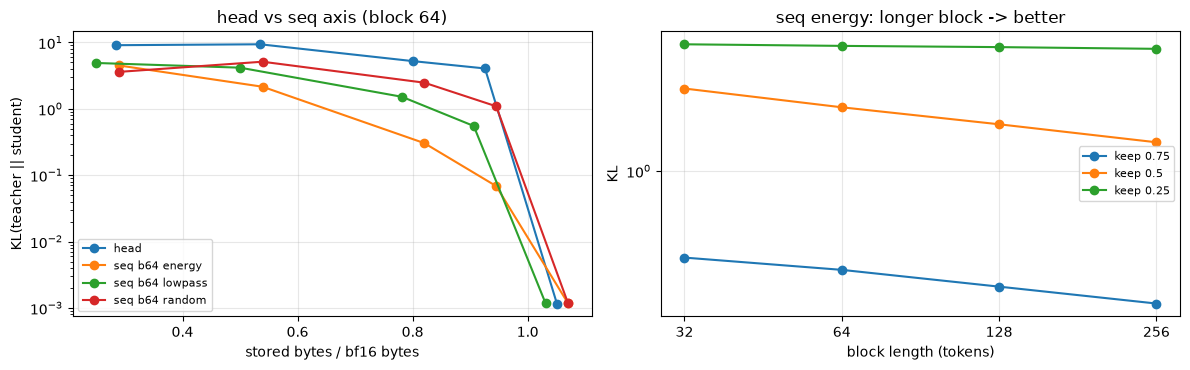

In [ ]:
R = (1.0, 0.875, 0.75, 0.5, 0.25)
rows_axis = keep_rows(tools.sweep_prefix(model, long_val, PREFIX, R, ("head",)), "head")
rows_axis += keep_rows(tools.sweep_prefix(model, long_val, PREFIX, R, ("lowpass", "energy", "random"),
                                          label="seq b64", block=64), "seq")
rows_axis += keep_rows(tools.sweep_prefix(model, long_val, PREFIX, (0.75, 0.5), ("energy",),
                                          label="seq b64 preRoPE", block=64, pre_rope=True), "seq")

print()
BLOCKS = (32, 64, 128, 256)
rows_block = []
for blk in BLOCKS:
    rows_block += keep_rows(tools.sweep_prefix(model, long_val, PREFIX, (0.75, 0.5, 0.25), ("energy",),
                                               label=f"seq b{blk}", block=blk), "seq")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
tools.plot_tradeoff([r for r in rows_axis if "preRoPE" not in r["mode"]], x="bytes", ax=[axes[0], axes[1]])
axes[1].clear()
for keep in (0.75, 0.5, 0.25):
    sel = [r for r in rows_block if r["keep_ratio"] == keep]
    axes[1].plot([r["block"] for r in sel], [r["kl"] for r in sel], "o-", label=f"keep {keep}")
axes[0].set(xlabel="stored bytes / bf16 bytes", title="head vs seq axis (block 64)")
axes[1].set(xscale="log", yscale="log", xlabel="block length (tokens)", ylabel="KL",
            title="seq energy: longer block -> better")
axes[1].set_xticks(BLOCKS, [str(b) for b in BLOCKS])
axes[1].minorticks_off()
for a in axes:
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()
BLOCK = 256   # (best value from 9.1)

### 9.2 Different allocation for K and V

- `keep_ratio=(k, v)` sets keep for K and V separately
- Compare with the equal-split (K = V) curve at the same bytes

              sym energy keep=0.875        bytes=0.916x kl=  0.0447 agree=0.887 ppl=     29.10
              sym energy keep=0.75         bytes=0.791x kl=  0.2028 agree=0.764 ppl=     35.20
              sym energy keep=0.625        bytes=0.666x kl=  0.5858 agree=0.624 ppl=     53.04
              sym energy keep=0.5          bytes=0.533x kl=  1.4128 agree=0.469 ppl=    124.47
              sym energy keep=0.375        bytes=0.408x kl=  2.8634 agree=0.338 ppl=    567.01
              sym energy keep=0.25         bytes=0.283x kl=  4.3511 agree=0.239 ppl=   2209.65
             asym energy keep=(0.875, 0.5) bytes=0.725x kl=  0.7304 agree=0.577 ppl=     54.91
             asym energy keep=(0.75, 0.5)  bytes=0.662x kl=  0.7299 agree=0.577 ppl=     57.43
             asym energy keep=(0.75, 0.375) bytes=0.600x kl=  1.2386 agree=0.476 ppl=     90.22
             asym energy keep=(0.625, 0.375) bytes=0.537x kl=  1.2966 agree=0.476 ppl=    102.35
             asym energy keep=(0.75, 0.25) byte

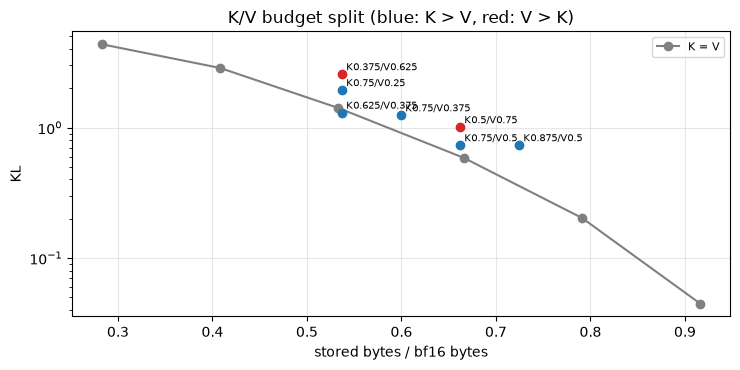

In [25]:
rows_sym = keep_rows(tools.sweep_prefix(model, long_val, PREFIX, (0.875, 0.75, 0.625, 0.5, 0.375, 0.25),
                                        ("energy",), label="sym", block=BLOCK), "seq")
ASYM = [(0.875, 0.5), (0.75, 0.5), (0.75, 0.375), (0.625, 0.375), (0.75, 0.25),
        (0.5, 0.75), (0.375, 0.625)]
rows_asym = keep_rows(tools.sweep_prefix(model, long_val, PREFIX, ASYM, ("energy",),
                                         label="asym", block=BLOCK), "seq")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot([r["bytes"] for r in rows_sym], [r["kl"] for r in rows_sym], "o-", c="gray", label="K = V")
for r in rows_asym:
    k, v = r["keep_ratio"]
    ax.scatter(r["bytes"], r["kl"], c="tab:blue" if k > v else "tab:red", zorder=3)
    ax.annotate(f"K{k}/V{v}", (r["bytes"], r["kl"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="stored bytes / bf16 bytes", ylabel="KL", yscale="log",
       title="K/V budget split (blue: K > V, red: V > K)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 9.3 Sequence-axis selector training

`SeqFreqSelector`: selects the top keep by the score `log|X| + bias[layer, K|V][head, freq, channel]`

- bias initialized to 0 → starts at the same point as energy top-k; gain = training effect
- Keeps the magnitude information; bias only corrects for frequencies/channels that matter to the attention result
- forward is 0/1 top-k, backward the sigmoid gradient near the boundary (STE, `seq_filter_ste`)
- loss: KL(teacher || student) on the trailing 128 tokens predicted on top of the compressed past. Model frozen
- Parameters 28 x 2 x 8 x 129 x 128 = 7.4M (1.2% of the model), training 84 batch x 3 epoch

=== keep 0.75  lr 0.02
step    0  KL 0.2115
step   84  KL 0.7792
step  168  KL 0.2290
=== keep 0.5  lr 0.05
step    0  KL 1.2321
step   84  KL 1.8925
step  168  KL 0.6408
=== keep 0.25  lr 0.05
step    0  KL 4.2753
step   84  KL 1.3810
step  168  KL 0.4292

 keep  bytes | energy KL      ppl | learned KL     ppl  agree
 0.75  0.791 |    0.2028     35.2 |     0.1641   31.46  0.782
  0.5  0.533 |    1.4128    124.5 |     0.4042   35.55  0.657
 0.25  0.283 |    4.3511   2209.7 |     0.5371   39.63  0.626


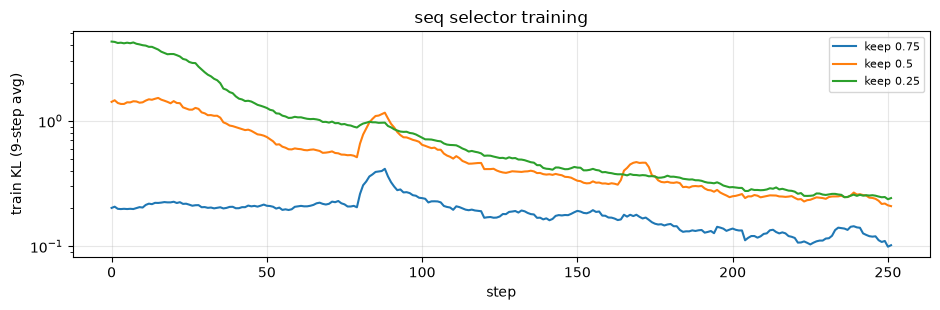

In [ ]:
SEQ_TRAIN = {0.75: 0.02, 0.5: 0.05, 0.25: 0.05}    # lr (values set by a prior sweep)
seq_selectors, seq_hist, rows_learn = {}, {}, []
for keep, lr in SEQ_TRAIN.items():
    tools.set_seed(0)
    sel = SeqFreqSelector(info["layers"], info["kv_heads"], info["head_dim"], BLOCK).to(model.device)
    print(f"=== keep {keep}  lr {lr}")
    seq_hist[keep] = tools.train_seq_selector(model, sel, long_train, PREFIX, keep,
                                              epochs=3, lr=lr, log_every=84)
    seq_selectors[keep] = sel
    torch.save(sel.state_dict(), RESULTS / "selectors" / f"seq_b{BLOCK}_keep{keep}.pt")
    row = tools.evaluate_prefix(model, long_val, PREFIX, keep, mode="learned", selector=sel, block=BLOCK)
    row["mode"] = "seq learned"
    rows_learn += keep_rows([row], "seq")

rows_energy = {r["keep_ratio"]: r for r in rows_sym}
rows_energy.update({r["keep_ratio"]: r for r in rows_block if r["block"] == BLOCK})
print(f"\n{'keep':>5} {'bytes':>6} | {'energy KL':>9} {'ppl':>8} | {'learned KL':>10} {'ppl':>7} {'agree':>6}")
for r in rows_learn:
    e = rows_energy[r["keep_ratio"]]
    print(f"{r['keep_ratio']:>5} {r['bytes']:>6.3f} | {e['kl']:>9.4f} {e['ppl']:>8.1f} | "
          f"{r['kl']:>10.4f} {r['ppl']:>7.2f} {r['agree']:>6.3f}")

fig, ax = plt.subplots(figsize=(9.5, 3.2))
for keep, hist in seq_hist.items():
    kd = torch.tensor([h["kd"] for h in hist])
    smooth = torch.nn.functional.avg_pool1d(kd[None, None], 9, 1, 4, count_include_pad=False)[0, 0]
    ax.plot(smooth, label=f"keep {keep}")
ax.set(xlabel="step", ylabel="train KL (9-step avg)", yscale="log", title="seq selector training")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 9.4 Coefficient quantization vs quantization without FFT

- Store the kept coefficients as int8/int4
- Coefficient magnitude differs by tens of times across frequencies (DC largest) → a separate scale per `coef_group` coefficients
- Baseline in the same byte range: KV quantized directly without FFT

In [ ]:
# Quantization baseline without FFT. block = size of the group sharing a scale (K: number of tokens, V: number of channels).
rows_raw = []
for c, groups in (("int8", (64,)), ("int4", (64,)), ("int2", (128, 64, 32))):
    for g in groups:
        rows_raw += keep_rows(tools.sweep_prefix(model, long_val, PREFIX, (1.0,), ("raw",),
                                                 label=f"raw {c} g{g}", coef=c, block=g), "raw")

print()
rows_q = []
# Effect of the scale group size (energy, int4)
for g in (None, 32, 8):
    rows_q += keep_rows(tools.sweep_prefix(model, long_val, PREFIX, (1.0, 0.5), ("energy",),
                                           label=f"int4 g{g}", block=BLOCK, coef="int4", coef_group=g), "seq+q")
print()
# Trained selector + quantization
for keep, sel in seq_selectors.items():
    for c, g in (("int8", 16), ("int4", 8)):
        r = tools.evaluate_prefix(model, long_val, PREFIX, keep, mode="learned", selector=sel,
                                  block=BLOCK, coef=c, coef_group=g)
        r["mode"] = f"learned + {c}"
        rows_q += keep_rows([r], "seq+q")
        print(f"{r['mode']:>16} keep={keep:<5} bytes={r['bytes']:.3f}x kl={r['kl']:.4f} "
              f"agree={r['agree']:.3f} ppl={r['ppl']:.2f}")

        raw int8 g64 raw keep=1.0          bytes=0.531x kl=  0.0011 agree=0.981 ppl=     27.56
        raw int4 g64 raw keep=1.0          bytes=0.281x kl=  0.0067 agree=0.955 ppl=     27.70
       raw int2 g128 raw keep=1.0          bytes=0.141x kl=  0.3368 agree=0.688 ppl=     36.24
        raw int2 g64 raw keep=1.0          bytes=0.156x kl=  0.1914 agree=0.760 ppl=     31.82
        raw int2 g32 raw keep=1.0          bytes=0.188x kl=  0.1114 agree=0.816 ppl=     30.06

       int4 gNone energy keep=1.0          bytes=0.289x kl=  3.2551 agree=0.329 ppl=    850.16
       int4 gNone energy keep=0.5          bytes=0.162x kl=  3.9821 agree=0.270 ppl=   1755.81
         int4 g32 energy keep=1.0          bytes=0.305x kl=  0.6456 agree=0.606 ppl=     56.59
         int4 g32 energy keep=0.5          bytes=0.166x kl=  2.9874 agree=0.324 ppl=    663.50
          int4 g8 energy keep=1.0          bytes=0.352x kl=  0.1152 agree=0.817 ppl=     31.19
          int4 g8 energy keep=0.5          bytes=

### 9.5 Low-byte range and controls

- FFT results up to 9.4 cluster at KL 0.4-0.55 and barely change as bytes shrink → need to check whether the compressed past is actually used
- Control: no compression of the past; keep only the last N tokens and discard the rest (`tools.evaluate_window`). N=0 discards the entire past = floor
- Lower limit of plain quantization: int2 with groups 256 and 512, int1
- FFT low-byte: train at keep 12.5% / 6.25% / 3.1%, then int8/int4/int2 coefficients
- Selected positions are stored as the smaller of a bitmask (17 bytes) and an index list (uint8 x keep) (`seq_codec`)

In [ ]:
def show(r):
    print(f"{r['mode']:>26} bytes={r['bytes']:.3f}x kl={r['kl']:.4f} agree={r['agree']:.3f} ppl={r['ppl']:.2f}")

# Control: keep only the last N tokens
for w in (0, 8, 32, 64, 128, 256):
    show(keep_rows([tools.evaluate_window(model, long_val, PREFIX, w)], "window")[0])

# Lower limit of plain quantization
print()
for c, groups in (("int2", (256, 512)), ("int1", (32, 128))):
    for g in groups:
        keep_rows(tools.sweep_prefix(model, long_val, PREFIX, (1.0,), ("raw",),
                                     label=f"raw {c} g{g}", coef=c, block=g), "raw")

# FFT low-byte
print()
for keep in (0.125, 0.0625, 0.03125):
    tools.set_seed(0)
    sel = SeqFreqSelector(info["layers"], info["kv_heads"], info["head_dim"], BLOCK).to(model.device)
    tools.train_seq_selector(model, sel, long_train, PREFIX, keep, epochs=3, lr=0.05, log_every=10**9)
    seq_selectors[keep] = sel
    torch.save(sel.state_dict(), RESULTS / "selectors" / f"seq_b{BLOCK}_keep{keep}.pt")
    for name, fam, kw in (("seq learned", "seq", {}),
                          ("learned + int8", "seq+q", dict(coef="int8", coef_group=16)),
                          ("learned + int4", "seq+q", dict(coef="int4", coef_group=8)),
                          ("learned + int2", "seq+q", dict(coef="int2", coef_group=8))):
        r = tools.evaluate_prefix(model, long_val, PREFIX, keep, mode="learned", selector=sel,
                                  block=BLOCK, **kw)
        r["mode"] = name
        keep_rows([r], fam)
        print(f"{name:>16} keep={keep:<8} bytes={r['bytes']:.3f}x kl={r['kl']:.4f} "
              f"agree={r['agree']:.3f} ppl={r['ppl']:.2f}")

## 10. Summary

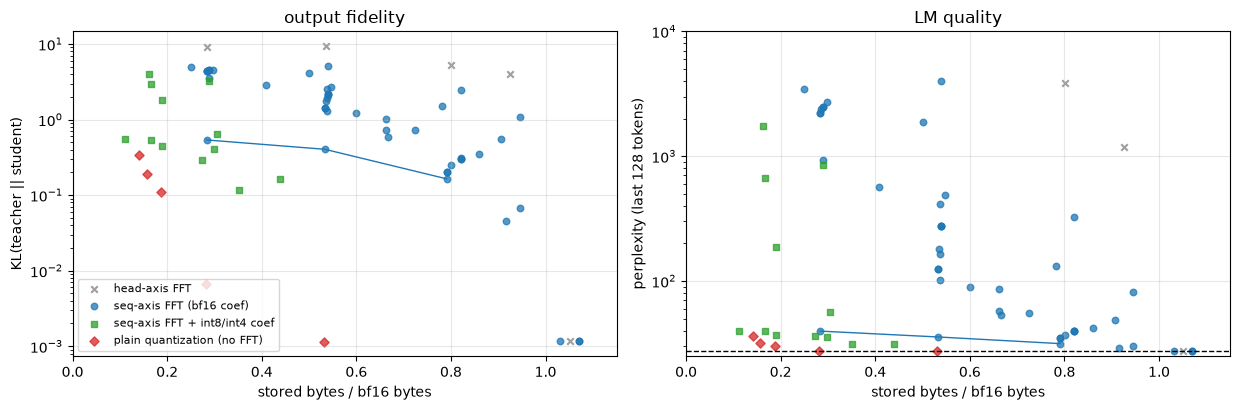

config                         bytes  saved       KL  agree       ppl
------------------------------------------------------------------------
original bf16 KV              1.000x   0.0%   0.0000  1.000     27.56
head-axis energy 50%          0.535x  46.5%   9.3809  0.040 261327.56
seq-axis lowpass 50% (b64)    0.500x  50.0%   4.1699  0.253   1870.77
seq-axis energy 50% (b64)     0.539x  46.1%   2.1527  0.396    276.63
seq-axis energy 50% (b256)    0.533x  46.7%   1.4128  0.469    124.47
seq-axis learned 75%          0.791x  20.9%   0.1641  0.782     31.46
seq-axis learned 50%          0.533x  46.7%   0.4042  0.657     35.55
seq-axis learned 25%          0.283x  71.7%   0.5371  0.626     39.63
learned 50% + int8 coef       0.299x  70.1%   0.4041  0.655     35.56
learned 25% + int8 coef       0.166x  83.4%   0.5374  0.626     39.64
learned 50% + int4 coef       0.189x  81.1%   0.4405  0.651     36.91
learned 25% + int4 coef       0.111x  88.9%   0.5480  0.624     39.89
raw int8 (no FFT)

In [ ]:
FAMILY_STYLE = {"head": ("tab:gray", "x"), "seq": ("tab:blue", "o"),
                "seq+q": ("tab:green", "s"), "raw": ("tab:red", "D"), "window": ("black", "^")}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
for fam, (color, marker) in FAMILY_STYLE.items():
    rows = [r for r in all_rows if r["family"] == fam]
    for a, key in zip(axes, ("kl", "ppl")):
        a.scatter([r["bytes"] for r in rows], [r[key] for r in rows], c=color, marker=marker,
                  s=22, alpha=0.75, label={"head": "head-axis FFT", "seq": "seq-axis FFT (bf16 coef)",
                                            "seq+q": "seq-axis FFT + int8/int4 coef",
                                            "raw": "plain quantization (no FFT)",
                                            "window": "keep last N tokens, drop the rest"}[fam])
window = sorted([r for r in all_rows if r["family"] == "window"], key=lambda r: r["bytes"])
for a, key in zip(axes, ("kl", "ppl")):
    a.plot([r["bytes"] for r in window], [r[key] for r in window], "-", c="black", lw=1)
    a.axhline(window[0][key], ls=":", c="black", lw=1)   # entire past discarded = floor
axes[1].axhline(off["ppl_teacher"], ls="--", c="k", lw=1, label="teacher")
axes[0].set(ylabel="KL(teacher || student)", title="output fidelity")
axes[1].set(ylabel="perplexity (last 128 tokens)", title="LM quality", ylim=(off["ppl_teacher"] * 0.9, 1e4))
for a in axes:
    a.set(xlabel="stored bytes / bf16 bytes", yscale="log", xlim=(0, 1.15))
    a.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()


def pick(mode_prefix, keep=None, **match):
    for r in all_rows:
        if r["mode"].startswith(mode_prefix) and (keep is None or r["keep_ratio"] == keep) \
                and all(r.get(k) == v for k, v in match.items()):
            return r
KEY_ROWS = [
    ("original bf16 KV", None),
    ("head-axis energy 50%", pick("head", 0.5)),
    ("seq-axis lowpass 50% (b64)", pick("seq b64 lowpass", 0.5)),
    ("seq-axis energy 50% (b64)", pick("seq b64 energy", 0.5)),
    ("seq-axis energy 50% (b256)", pick("seq b256 energy", 0.5)),
    ("seq-axis learned 75%", pick("seq learned", 0.75)),
    ("seq-axis learned 50%", pick("seq learned", 0.5)),
    ("seq-axis learned 25%", pick("seq learned", 0.25)),
    ("learned 50% + int8 coef", pick("learned + int8", 0.5)),
    ("learned 25% + int8 coef", pick("learned + int8", 0.25)),
    ("learned 50% + int4 coef", pick("learned + int4", 0.5)),
    ("learned 25% + int4 coef", pick("learned + int4", 0.25)),
    ("raw int8 (no FFT)", pick("raw int8")),
    ("raw int4 (no FFT)", pick("raw int4")),
    ("raw int2 g32 (no FFT)", pick("raw int2 g32")),
    ("raw int2 g128 (no FFT)", pick("raw int2 g128")),
    ("learned 12.5% + int4 coef", pick("learned + int4", 0.125)),
    ("learned 3.1% + int4 coef", pick("learned + int4", 0.03125)),
    ("keep last 256 tokens only", pick("window last 256")),
    ("keep last 64 tokens only", pick("window last 64")),
    ("keep last 8 tokens only", pick("window last 8")),
    ("discard entire past (floor)", pick("window last 0")),
]
print(f"{'config':<28} {'bytes':>7} {'saved':>6} {'KL':>8} {'agree':>6} {'ppl':>9}")
print("-" * 72)
for name, r in KEY_ROWS:
    if r is None:
        r = {"bytes": 1.0, "kl": 0.0, "agree": 1.0, "ppl": off["ppl_teacher"]}
    print(f"{name:<28} {r['bytes']:>6.3f}x {1 - r['bytes']:>6.1%} {r['kl']:>8.4f} {r['agree']:>6.3f} {r['ppl']:>9.2f}")

summary["seq_axis"] = [{k: (list(v) if isinstance(v, tuple) else v) for k, v in r.items()
                        if k in ("family", "mode", "keep_ratio", "block", "coef", "coef_group", "window",
                                 "bytes", "kl", "agree", "ppl")} for r in all_rows]
summary["seq_axis_teacher_ppl"] = off["ppl_teacher"]
(RESULTS / "fft_kv_summary.json").write_text(json.dumps(summary, indent=1, default=str))
print(f"\n-> {RESULTS / 'fft_kv_summary.json'} updated")

## 11. Conclusion

Measurement conditions
- Model: Qwen3-0.6B (bf16)
- Data: gutenberg validation, 16 batch x 2 sentences
- Scheme: compress the first 512 tokens, evaluate on the following 128 tokens (4,096 total)
- Reference: teacher (original KV) ppl 27.56
- Bytes: measured size of the storage-format tensors / original bf16 KV size

### Summary
- Conclusion: in this evaluation FFT compression loses to the two simplest baselines (plain quantization, keeping only recent tokens)
- Plain int4 quantization: ppl 27.7 at 0.281x (original 27.6), practically lossless
- Keeping only the last 64 tokens as original: ppl 32.7 at 0.125x
- Best FFT setting (sequence axis + learned selection + int4 coefficients): ppl 39.9 at 0.111x, 40-45 even down to 0.02x
- Discarding the entire past gives ppl 46.2 → the FFT-compressed past conveys almost no information
- The plan's head_dim-axis FFT: collapses to ppl 261,328 at the same 50%

### Size and quality

| Config | Memory | Memory saved | KL | top-1 agreement | ppl |
|---|---|---|---|---|---|
| original bf16 KV | 1.000x | – | 0 | 1.000 | 27.56 |
| head-axis energy 50% (plan's method) | 0.535x | 46.5% | 9.38 | 0.040 | 261,328 |
| seq-axis energy 50% (block 64) | 0.539x | 46.1% | 2.15 | 0.396 | 276.6 |
| seq-axis energy 50% (block 256) | 0.533x | 46.7% | 1.41 | 0.469 | 124.5 |
| **seq-axis learned 50%** | 0.533x | 46.7% | **0.40** | 0.657 | **35.6** |
| **learned 50% + int8 coef** | **0.299x** | **70.1%** | 0.40 | 0.655 | 35.6 |
| **learned 50% + int4 coef** | **0.189x** | **81.1%** | 0.44 | 0.651 | 36.9 |
| **learned 25% + int4 coef** | **0.111x** | **88.9%** | 0.55 | 0.624 | 39.9 |
| raw int8 (no FFT) | 0.531x | 46.9% | 0.001 | 0.981 | 27.56 |
| raw int4 (no FFT) | 0.281x | 71.9% | 0.007 | 0.955 | 27.70 |
| raw int2, group 32 (no FFT) | 0.188x | 81.2% | 0.11 | 0.816 | 30.06 |
| raw int2, group 128 (no FFT) | 0.141x | 85.9% | 0.34 | 0.688 | 36.24 |
| learned 12.5% + int4 coef | 0.070x | 93.0% | 0.61 | 0.607 | 41.4 |
| learned 3.1% + int4 coef | 0.020x | 98.0% | 0.64 | 0.593 | 42.0 |
| raw int1, group 32 (no FFT) | 0.125x | 87.5% | 6.95 | 0.082 | 19,069 |
| keep last 256 tokens only (no compression) | 0.500x | 50.0% | 0.09 | 0.857 | 29.04 |
| keep last 64 tokens only (no compression) | 0.125x | 87.5% | 0.24 | 0.771 | 32.71 |
| keep last 8 tokens only (no compression) | 0.016x | 98.4% | 0.47 | 0.680 | 39.15 |
| **discard entire past (floor)** | 0x | 100% | 0.66 | 0.651 | 46.20 |

Step-by-step gains at 50% (about 0.53x)

| Step | KL | ppl | vs previous |
|---|---|---|---|
| head_dim-axis FFT, energy top-k | 9.38 | 261,328 | – |
| → sequence axis (block 64) | 2.15 | 276.6 | KL down 4.4x |
| → block 256 | 1.41 | 124.5 | KL down 1.5x |
| → selector training | 0.40 | 35.6 | KL down 3.5x |
| → int8 coefficients (bytes 0.533x → 0.299x) | 0.40 | 35.6 | quality kept, 44% further byte savings |

### Core algorithm
1. **Sequence-axis block rFFT** (`seq_codec`)
   - Split the cache into 256-token blocks; rFFT the length-256 time series per (head, channel) (129 coefficients)
   - Stored: real/imag parts of the selected coefficients + selected-position bitmask (129 bits)
2. **Leak-free prefix evaluation** (`evaluate_prefix`)
   - Block FFT mixes future information within a block into the past → compress the past span only
   - A query attends only to compressed past blocks, same as the real KV cache usage order
3. **Learned coefficient selection** (`SeqFreqSelector`)
   - score = log|coef| + bias[layer, K/V, head, freq, channel]
   - bias starts at 0 → starts from the same point as energy top-k; top-k is passed through with STE
   - Trained on the trailing-token KL(teacher‖student) alone, model frozen
   - 7.4M parameters (1.2% of the model), 84 batch x 3 epoch
4. **Coefficient quantization per frequency group** (`coef_group`)
   - A separate scale per 8-16 coefficients
   - DC is tens of times larger than the other coefficients, so a single shared scale wipes small coefficients to 0
5. **Measured byte accounting**
   - The storage format is actually built, and quality is measured after reconstructing from those values alone
   - Includes bitmask and scale

### Findings from the experiments
1. **head_dim axis: not compressible**
   - Energy fraction in half the coefficients: K 0.79, V 0.84 vs noise 0.84 (Section 2)
   - KL 4.06 when dropping 12.5% of the coefficients, ppl 260k when dropping 50%
   - The hypothesis "K/V latents are sparse in the FFT basis" is rejected on the head_dim axis
2. **Sparsity reference line = 0.84**
   - With per-sample sorting by magnitude, even structureless noise has 84% of the energy in half the coefficients
3. **Sequence axis: structure exists**
   - KL 9.38 → 2.15 at the same 50%
   - Cause: correlation between the K/V of adjacent tokens
4. **Differences between methods**
   - keep 75% KL: energy 0.30, lowpass 1.52, random 2.48
   - lowpass and random differ little → the argument "K/V change slowly over time" looks weak
5. **Block length: longer is better**
   - keep 50%, blocks 32·64·128·256 → KL 2.70·2.15·1.75·1.41
   - trade-off: recent tokens are stored as original until a block fills
6. **RoPE: not the cause of the loss**
   - K's sequence-axis spectrum has a RoPE frequency peak (bin ≈ 41)
   - Undoing RoPE before compression gives "KL 0.304 → 0.306, the same"
7. **Separate K/V allocation: no effect**
   - K is more sensitive (preliminary run with 256 tokens, block 32: compressing K only KL 2.08 vs V only 1.14)
   - At the same 0.662x, K-first allocation 0.73 vs V-first 1.00
   - Worse than the equal split (0.666x, 0.59)
# 8. **Selector training: effect grows sharply with stronger compression**
   - energy → learned KL: keep 75% 0.20 → 0.16, 50% 1.41 → 0.40 (3.5x), 25% 4.35 → 0.54 (8.1x, ppl 2,210 → 39.6)
   - Selection by signal energy (L2) ≠ selection by attention output
   - Training takes about 1 min per setting; train KL < val KL, mild overfitting
9. **Coefficient quantization**
   - int8: quality kept, only memory drops (KL 0.40 → 0.40, 0.533x → 0.299x)
   - int4: depends on the scale group size (at keep 100%: no grouping KL 3.26, group 32 0.65, group 8 0.12)
10. **Comparison with plain quantization**
    - raw int4: KL 0.007 at 0.281x, practically lossless
    - raw int2 (group 32): ppl 30.1 at 0.188x > learned 50% + int4 of the same size (ppl 36.9)
    - Loss from dropping coefficients > quantization error
    - Below 2 bits is not viable: raw int1 (group 32) gives ppl 19,069 at 0.125x
11. **FFT loses to the control (keeping only the last N tokens)**
    - Keeping the last 64 tokens: 0.125x ppl 32.7; keeping the last 8 tokens: 0.016x ppl 39.2
    - FFT: 0.111x ppl 39.9, 0.020x ppl 42.0
    - Untrained energy top-k (KL 1.41-4.35) is worse than discarding the entire past (KL 0.66) → a damaged cache disrupts attention more than no cache
12. **Why the FFT curve is flat**
    - From 0.28x → 0.02x, KL 0.53 → 0.64, pinned near discarding the entire past (0.66)
    - A scheme that preserves information should lose quality as bytes shrink
    - Most of the gain from selector training (item 8) is the effect of "making the damaged past harmless"
13. **Limits of the evaluation task**
    - Full-context ppl 27.6 vs no context 46.2; the last 64 tokens recover most of that gap
    - Next-token prediction on a novel leans heavily on recent context, so it undervalues preserving the distant past

### Limitations
- Small test set
- Only a single 512-token compressed span / very long contexts and block-wise updates during generation are untested
- Speed -> added FFT compute cost

### Future
1. **Evaluate on tasks that need the distant past**
   - Tasks that cannot be solved from recent tokens alone, such as passkey retrieval and long-document QA
   - The value of lossy compression can only be judged where context truncation fails
2. **Apply FFT to the quantization residual**
   - Store as raw int2 and correct only the residual with sequence-axis FFT (values are not replaced by coefficients)
3. **Per-frequency bit allocation**
   - Instead of keep/drop, DCT-based transform coding with a different bit count per frequency
4. **Asymmetric quantization of FFT coefficients: tested, no effect**
   - keep 25% + int4: symmetric 0.111x KL 0.54 vs asymmetric 0.127x KL 0.53 (storing min/max only adds bytes)